# Round 6: relation-aware positives against relation-typed negatives

Rounds 1-2 weighted the **negatives** of MulSupCon by relation type
(RTN). This round adds the **positive** side, in the same pipeline,
data split, settings and seeds, so that every method is compared like
for like on the same evaluation images:

| Variant | Positives | Negatives |
|---|---|---|
| MulSupCon (rounds 1-2) | every candidate with the anchor label, equal weight | equal weight |
| RTN (ours, rounds 1-2) | as MulSupCon | weighted by relation type |
| ALL | one anchor per image; candidates with the same label set | equal weight |
| ANY | one anchor per image; candidates sharing at least one label | equal weight |
| Similarity-Dissimilarity | ANY, each weighted by similarity x dissimilarity | equal weight |
| MulSupCon + Sim-Diss weights | as MulSupCon, each weighted by similarity x dissimilarity | equal weight |
| RTN + Sim-Diss weights | as MulSupCon, each weighted by similarity x dissimilarity | weighted by relation type |

The Similarity-Dissimilarity loss (Huang, Long and Luo, TMLR 2026)
weights a positive by K_s = |S n T| / |S| (the share of the anchor's
labels it has) times K_d = 1 / (1 + |T \ S|) (fewer extra labels,
more weight). In the paper's Eq. 13 the factor is written inside the
log, multiplying the positive's exponential; there it only adds a
constant to the loss, so the gradients are the same as ANY's (Step 3
checks this). Here the factor multiplies each positive's
log-probability term, so that it changes how strongly each positive
is pulled, which is the reweighting the paper describes. The
notebook says so in its limitations; it is worth confirming the
intended form with the authors.

The last three rows form a 2 x 2 with MulSupCon and RTN: positives
(equal / Sim-Diss weights) x negatives (equal / relation types). It
shows which side helps the tail more and whether the two add up.

Also included, for the report: an analysis of the dataset (label
frequency, labels per image, co-occurrence, imbalance) and the time
one training takes on the GPU and on the CPU.

## Step 0: setup

In [2]:
import glob
import hashlib
import importlib
import json
import os
import sys
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Image, display

if not os.path.exists("context_reliance_check.py"):
    raise SystemExit("Put context_reliance_check.py in the same folder "
                     "as this notebook.")
import context_reliance_check as crc
importlib.reload(crc)
if not hasattr(crc, "related_labels"):
    raise SystemExit("context_reliance_check.py is an older version. "
                     "Replace it with the latest one.")
pd.set_option("display.max_colwidth", None)    # show full table cells
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"numpy {np.__version__}, pandas {pd.__version__}, "
      f"torch {torch.__version__}")
if DEVICE == "cuda":
    props = torch.cuda.get_device_properties(0)
    print(f"Device: {props.name} ({props.total_memory / 2**30:.1f} GB)")
else:
    print(f"Device: CPU (this PyTorch build has CUDA: {torch.version.cuda})")

numpy 2.5.4, pandas 3.1.0, torch 2.11.0+cu130
Device: NVIDIA GeForce RTX 4070 Laptop GPU (8.0 GB)


## Step 1: settings

In [3]:
DATA = "coco_mlt"
OUT = os.path.join(DATA, "contrastive")      # same folder as rounds 1-2
SEEDS = [42, 43, 44]
SELECT_SEED = 42
DEV_FRAC = 0.2
SPLIT_SEED = 0
RELATED_PCT = 5
BOOTSTRAP = 10000
RETRAIN = False           # True reruns everything, ignoring saved runs
WORKERS = "auto"          # trainings at the same time ("auto" or a number)
BINARY_BASELINES = True   # False skips ALL and ANY (6 runs fewer)
TIME_CPU = True           # time one training's steps on the CPU too
ALLOW_CPU = False
QUICK_TEST = False        # True = tiny run to test the code only

# Rounds 1-2 variants, identical settings, so their saved runs are reused
VARIANTS = [
    ("bce", "BCE (no contrastive pretraining)", "bce",
     [dict(lrp=0.1), dict(lrp=1.0)]),
    ("mulsupcon", "MulSupCon", "uniform", [dict()]),
    ("ours", "RTN: MulSupCon + relation-typed negatives (ours)", "relation",
     [dict(alpha=1.0), dict(alpha=4.0)]),
]
# Round 6: the positive side (no settings to choose, so 3 seeds each)
if BINARY_BASELINES:
    VARIANTS += [
        ("all", "ALL: same label set as the anchor image", "all", [dict()]),
        ("any", "ANY: at least one shared label", "any", [dict()]),
    ]
VARIANTS += [
    ("simdiss", "Similarity-Dissimilarity (Huang et al., 2026)", "simdiss",
     [dict()]),
    ("mul_sd", "MulSupCon + Sim-Diss positive weights", "mul_simdiss",
     [dict()]),
    ("ours_sd", "RTN + Sim-Diss positive weights", "relation_simdiss",
     [dict(alpha=4.0)]),       # RTN's setting chosen in round 1
]
ROUND6 = [k for k, _, _, _ in VARIANTS if k not in ("bce", "mulsupcon", "ours")]
NAME = {k: n for k, n, _, _ in VARIANTS}
SHORT = {"bce": "BCE", "mulsupcon": "MulSupCon", "ours": "RTN (ours)",
         "all": "ALL", "any": "ANY", "simdiss": "Sim-Diss",
         "mul_sd": "MulSupCon + SD", "ours_sd": "RTN + SD"}


def setting_text(s):
    words = {"alpha": "alpha {:g}", "tau": "temperature {:g}",
             "lrp": "backbone lr x{:g}"}
    return ", ".join(words[k].format(v) for k, v in s.items()) or "-"


def setting_tag(s):
    return "-".join(f"{k}{v:g}" for k, v in s.items()) or "default"


if DEVICE == "cpu" and not (QUICK_TEST or ALLOW_CPU):
    raise SystemExit(
        "No GPU is visible to this notebook. In Jupyter or VS Code, pick the "
        "kernel (Python environment) you used for rounds 1-2, then Restart & "
        "Run All. (To run on the CPU anyway, set ALLOW_CPU = True.)")
for sub in ("runs", "backbones", "logs"):
    os.makedirs(os.path.join(OUT, sub), exist_ok=True)
pd.DataFrame([("6" if k in ROUND6 else "1-2", n, kind,
               " / ".join(setting_text(s) for s in grid))
              for k, n, kind, grid in VARIANTS],
             columns=["round", "variant", "kind", "settings"])

,round,variant,kind,settings
0,1-2,BCE (no contrastive pretraining),bce,backbone lr x0.1 / backbone lr x1
1,1-2,MulSupCon,uniform,-
2,1-2,RTN: MulSupCon + relation-typed negatives (ours),relation,alpha 1 / alpha 4
3,6,ALL: same label set as the anchor image,all,-
4,6,ANY: at least one shared label,any,-
5,6,"Similarity-Dissimilarity (Huang et al., 2026)",simdiss,-
6,6,MulSupCon + Sim-Diss positive weights,mul_simdiss,-
7,6,RTN + Sim-Diss positive weights,relation_simdiss,alpha 4


## Step 2: method code

The code of rounds 1-2 plus the positive-side losses (`all`, `any`,
`simdiss`, `mul_simdiss`, `relation_simdiss`). The losses of rounds
1-2 are unchanged, so their saved runs stay valid; Step 3 checks this.
This cell saves the code as `relation_contrastive_method.py`.

In [4]:
%%writefile relation_contrastive_method.py
# ---------------------------------------------------------------------------
# Core code for the relation-aware contrastive experiment (frozen CLIP features)
#
# MulSupCon follows the official implementation (Zhang & Wu, AAAI 2024,
# github: MulSupCon, vector-data configuration): MLP backbone, projection
# head, MoCo-style momentum key encoder and queue, MulSupCon positives (each
# label of an anchor separately), WeightedSupCon loss with 1/len(rows)
# weights, 50% feature masking, Adam + cosine warm restarts, then fine-tuning
# with BCE (backbone lr x0.1, ReduceLROnPlateau, early stopping on a dev set).
# The other variants change only how negatives are weighted inside that loss,
# except the round-6 variants, which change the positives:
#   ALL / ANY (image anchors): positives are candidates with the same label
#                 set / sharing at least one label (binary definitions).
#   Similarity-Dissimilarity (Huang, Long and Luo, TMLR 2026, Eqs. 13-15):
#                 ANY positives, each weighted by K_s x K_d with
#                 K_s = |S n T| / |S| and K_d = 1 / (1 + |T \ (S n T)|),
#                 S the anchor's and T the candidate's label set.
#                 As printed, Eq. 13 puts the factor inside the log, where it
#                 adds a constant and leaves the gradients equal to ANY's (the
#                 self-test shows this); the factor is therefore applied to
#                 each positive's log-probability term, which is what changes
#                 how strongly each positive is pulled.
#   mul_simdiss / relation_simdiss: MulSupCon's per-label anchors with the
#                 same positive weights, with uniform or relation-typed
#                 negatives (the positives x negatives comparison).
#
# SCHaNe (Long et al. 2023) and LCL (Suresh & Ong 2021) have no official code
# for this setting; their weights are implemented from the papers' equations:
#   SCHaNe Eq. 3: negative k of anchor i gets
#                 beta_k = |N| exp(s_ik/tau) / sum_{n in N} exp(s_in/tau)
#   LCL Eq. 3:    every term of anchor i is weighted by w_{i, y_a}, the
#                 anchor's weighting-network probability for candidate a's
#                 class (w_{i, y_i} for positives, numerator included).
#                 Multi-label adaptation: sigmoid probabilities (BCE-trained
#                 weighting network) and, for a negative with several labels,
#                 the largest of the anchor's probabilities for those labels.
# ---------------------------------------------------------------------------
import copy
import math
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

CODE_VERSION = "2026-10-30"     # part of the saved-run tag (unchanged: same computation)

# Official settings (codes/config/pretrain_yeast.yaml and train_yeast.yaml)
PRETRAIN = dict(epochs=150, iters_per_epoch=1000, batch_size=64, cap_Q=256,
                momentum=0.999, temperature=0.1, out_dim=256, n_hidden=1,
                lr=4e-4, weight_decay=1e-5, T_0=50, T_mult=2, eta_min=1e-4,
                mask_p=0.5, running_alpha=0.98)
# Fine-tuning: official rules (BCE, Adam, backbone lr x0.1, ReduceLROnPlateau,
# early stopping after 20 epochs without a lower dev loss, test predictions
# at the lowest dev loss). One change: the official cap of 30 epochs (set for
# the 14-label yeast data) is raised to max_epochs so that early stopping,
# not the cap, ends training. The official-cap result is read from the same
# run (its first 30 epochs are identical) and reported as a secondary check.
FINETUNE = dict(official_epochs=30, max_epochs=400, iters_per_epoch=50,
                batch_size=32, lr=4e-4, lrp=0.1, plateau_factor=0.1,
                plateau_patience=2, plateau_cooldown=1, plateau_threshold=1e-3,
                early_stop_patience=20)


# --------------------------- data helpers ----------------------------------
def iterative_split(Y, test_frac, seed):
    """Iterative stratification for multi-label data (Sechidis et al., 2011).
    Returns 0 (fit) / 1 (dev) for each row, keeping every label's share close
    to the target in both parts."""
    rng = np.random.default_rng(seed)
    Y = np.asarray(Y, dtype=bool)
    n = Y.shape[0]
    frac = np.array([1.0 - test_frac, test_frac])
    desired = frac * n
    desired_label = np.outer(frac, Y.sum(0)).astype(float)
    remaining = np.ones(n, dtype=bool)
    assign = -np.ones(n, dtype=int)
    while True:
        rem = Y[remaining].sum(0)
        if rem.sum() == 0:
            break
        label = int(np.argmin(np.where(rem > 0, rem, np.iinfo(np.int64).max)))
        idx = np.flatnonzero(remaining & Y[:, label])
        rng.shuffle(idx)
        for i in idx:
            d = desired_label[:, label]
            cand = np.flatnonzero(d == d.max())
            if cand.size > 1:
                ds = desired[cand]
                cand = cand[ds == ds.max()]
            s = int(rng.choice(cand)) if cand.size > 1 else int(cand[0])
            assign[i] = s
            remaining[i] = False
            desired_label[s] -= Y[i]
            desired[s] -= 1
    for i in np.flatnonzero(remaining):          # images without labels
        s = int(np.argmax(desired))
        assign[i] = s
        desired[s] -= 1
    return assign


class Scaler:
    """sklearn.preprocessing.StandardScaler (population std, zero std -> 1)."""

    def fit(self, X):
        self.mean = X.mean(0)
        std = X.std(0)
        self.scale = np.where(std == 0, 1.0, std)
        return self

    def transform(self, X):
        return ((X - self.mean) / self.scale).astype(np.float32)


class OfficialSampler:
    """Batches exactly as the official RandomSampler: indices shuffled once
    by parse_data (RandomState(seed)), again by the sampler (RandomState(seed)),
    then read cyclically, reshuffling each time the pointer wraps."""

    def __init__(self, n, batch_size, seed):
        indices = list(range(n))
        np.random.RandomState(seed=seed).shuffle(indices)     # parse_data
        self.indices = np.array(indices)
        self.rs = np.random.RandomState(seed=seed)            # Sampler
        self.rs.shuffle(self.indices)
        self.ptr, self.batch_size = 0, batch_size

    def next(self):
        out = np.empty(self.batch_size, dtype=np.int64)
        for j in range(self.batch_size):
            out[j] = self.indices[self.ptr]
            self.ptr = (self.ptr + 1) % len(self.indices)
            if not self.ptr:
                self.rs.shuffle(self.indices)
        return out


def mask_views(x, p, generator):
    """Official vector augmentation: each feature kept with probability 1-p."""
    if not p:
        return x
    keep = (torch.rand(x.shape, generator=generator, device=x.device) > p)
    return x * keep.to(x.dtype)


# --------------------------- models (official) ------------------------------
class Backbone(nn.Module):
    """codes/backbone.py: MLP (vector data)."""

    def __init__(self, in_dim, dropout=0.2):
        super().__init__()
        self.mlp = nn.Sequential(
            nn.Linear(in_dim, 256), nn.ReLU(), nn.Dropout(p=dropout),
            nn.Linear(256, 512), nn.ReLU(), nn.Dropout(p=dropout),
            nn.Linear(512, 256), nn.ReLU(), nn.Dropout(p=dropout))

    def forward(self, x):
        return self.mlp(x)


class ProjHead(nn.Module):
    """codes/models.py: MLP projection head."""

    def __init__(self, in_dim=256, out_dim=256, n_hidden=1):
        super().__init__()
        layers, d = [], in_dim
        for _ in range(n_hidden):
            nxt = d // 2 if d >= 2 * out_dim else out_dim
            layers += [nn.Linear(d, nxt), nn.BatchNorm1d(nxt), nn.ReLU(),
                       nn.Dropout(p=0.1)]
            d = nxt
        layers.append(nn.Linear(d, out_dim))
        self.mlp = nn.Sequential(*layers)

    def forward(self, x):
        return self.mlp(x)


class Encoder(nn.Module):
    def __init__(self, in_dim, out_dim=256, n_hidden=1):
        super().__init__()
        self.backbone = Backbone(in_dim)
        self.proj_head = ProjHead(256, out_dim, n_hidden)

    def forward(self, x):
        return self.proj_head(self.backbone(x))


class Classifier(nn.Module):
    """codes/models.py 'Simple': backbone + linear output layer."""

    def __init__(self, in_dim, n_class):
        super().__init__()
        self.backbone = Backbone(in_dim)
        self.output_layer = nn.Linear(256, n_class)

    def forward(self, x):
        return self.output_layer(self.backbone(x))


class PretrainModel(nn.Module):
    """codes/models.py PretrainModel (MoCo queue + momentum key encoder)."""

    def __init__(self, in_dim, n_class, cap_Q, momentum, out_dim, n_hidden):
        super().__init__()
        self.encoder_q = Encoder(in_dim, out_dim, n_hidden)
        self.encoder_k = Encoder(in_dim, out_dim, n_hidden)
        self.m, self.cap_Q = momentum, cap_Q
        self.register_buffer("QueuePtr", torch.tensor([0], dtype=torch.int32))
        self.register_buffer("QueueFull", torch.tensor([False]))
        self.register_buffer("MoCoQueue", nn.functional.normalize(
            torch.randn(out_dim, cap_Q), dim=0))
        self.register_buffer("LabelQueue", torch.zeros(cap_Q, n_class))
        for pq, pk in zip(self.encoder_q.parameters(),
                          self.encoder_k.parameters()):
            pk.data.copy_(pq.data)
            pk.requires_grad = False
        self._q = list(self.encoder_q.parameters())
        self._k = list(self.encoder_k.parameters())
        # Queue pointer and 'full' flag kept on the CPU as well, so no GPU
        # synchronisation is needed each step (same values as the buffers).
        self._ptr, self._full = 0, False

    @torch.no_grad()
    def momentum_update(self):
        torch._foreach_mul_(self._k, self.m)
        torch._foreach_add_(self._k, self._q, alpha=1 - self.m)

    def forward(self, x1, x2, labels):
        """Returns (scores, reference labels). Same order of operations as the
        official forward(): momentum update, queries, keys, clone of the
        queue, enqueue, then scores (batch keys only until the queue is
        full, then batch keys + queue)."""
        if self.training:
            self.momentum_update()
        q = nn.functional.normalize(self.encoder_q(x1), dim=1)
        with torch.no_grad():
            k = nn.functional.normalize(self.encoder_k(x2), dim=1)
        queue_k = self.MoCoQueue.clone().detach()
        queue_labels = self.LabelQueue.clone().detach()
        if self.training:
            B = len(labels)
            assert not self.cap_Q % B
            ptr = self._ptr
            self.MoCoQueue[:, ptr:ptr + B] = k.T
            self.LabelQueue[ptr:ptr + B] = labels
            ptr = (ptr + B) % self.cap_Q
            self._ptr = ptr
            self.QueuePtr.fill_(ptr)
            if not ptr:
                self._full = True
                self.QueueFull.fill_(True)
        batch_score = q @ k.T
        if not self._full:
            return batch_score, labels
        scores = torch.cat([batch_score, q @ queue_k], dim=1)
        ref_labels = torch.cat([labels, queue_labels], dim=0)
        return scores, ref_labels


# --------------------------- losses -----------------------------------------
def mulsupcon_loss(scores, batch_labels, ref_labels, tau, mode="uniform",
                   relation=None, alpha=0.0, p_anchor=None):
    """MulSupCon loss with optional negative weights.

    One row per (anchor image, anchor label k), in the official order
    (torch.where on the batch labels). Positives of a row: candidates that
    carry label k (the anchor's own key included). Loss per row:
        -(1/|P|) sum_p log( w_p e^{s_p/tau} / sum_a w_a e^{s_a/tau} )
    averaged over rows (official weights 1/len(rows)). With all w = 1 this is
    exactly the official MulSupCon/WeightedSupCon loss.

    mode:
      uniform    : w = 1 (MulSupCon)
      schane     : negatives w = |N| e^{s/tau} / sum_N e^{s/tau}
                   (Long et al. 2023, Eq. 3), positives 1
      lcl        : LCL Eq. 3 (Suresh & Ong 2021), weights from the anchor's
                   weighting-network probabilities p_anchor (B x C):
                   positives w = p_anchor[i, k] (numerator included),
                   negatives w = max over the candidate's labels c of
                   p_anchor[i, c]
      relation   : negatives w = 1 + alpha * max_c R[k, c] over the
                   candidate's labels c (relation given as list of
                   (value, mask matrix L x L)); positives 1
      relation_schane : negatives w = beta (SCHaNe, Eq. 3) x (1 + alpha *
                   max_c R[k, c]); positives 1 (round-2 combination)
      mul_simdiss / relation_simdiss : positive p of a row from anchor image i
                   counts K_s(i, p) x K_d(i, p) times (its log-probability term
                   is multiplied by that factor); negatives uniform / as in
                   'relation' (round 6)
      any / all / simdiss : image anchors (one row per image), see
                   image_supcon_loss_reference
    """
    if mode in IMAGE_MODES:
        return image_supcon_loss_reference(scores, batch_labels, ref_labels, tau, mode)
    img_idx, lab_idx = torch.where(batch_labels == 1)
    logits = scores[img_idx] / tau                        # R x Q
    pos = ref_labels[:, lab_idx].T > 0.5                  # R x Q
    n_pos = pos.sum(1)
    pos_w = torch.ones_like(logits)
    if mode in POSW_MODES:
        pos_w = simdiss_weights(batch_labels, ref_labels)[img_idx]
    if mode in ("uniform", "mul_simdiss"):
        log_prob = logits - torch.logsumexp(logits, dim=1, keepdim=True)
    else:
        if mode == "schane":
            masked = logits.masked_fill(pos, float("-inf"))
            n_neg = (~pos).sum(1, keepdim=True).clamp_min(1)
            log_beta = (masked - torch.logsumexp(masked, dim=1, keepdim=True)
                        + torch.log(n_neg.to(logits.dtype)))
            logw = torch.where(pos, torch.zeros_like(logits), log_beta)
        elif mode == "lcl":
            pa = p_anchor[img_idx]                                      # R x C
            w_pos = pa[torch.arange(len(lab_idx)), lab_idx].unsqueeze(1)  # R x 1
            w_cand = (pa.unsqueeze(1) * ref_labels.unsqueeze(0)).amax(2)  # R x Q
            w = torch.where(pos, w_pos.expand_as(logits), w_cand)
            logw = torch.log(w.clamp_min(1e-6))
        elif mode in ("relation", "relation_simdiss"):
            score = torch.zeros_like(logits)
            refT = ref_labels.T                                         # C x Q
            for value, M in relation:
                has = (M[lab_idx] @ refT) > 0.5                         # R x Q
                score = torch.maximum(score, has.to(logits.dtype) * value)
            logw = torch.where(pos, torch.zeros_like(logits),
                               torch.log1p(alpha * score))
        elif mode == "relation_schane":
            masked = logits.masked_fill(pos, float("-inf"))
            n_neg = (~pos).sum(1, keepdim=True).clamp_min(1)
            log_beta = (masked - torch.logsumexp(masked, dim=1, keepdim=True)
                        + torch.log(n_neg.to(logits.dtype)))
            score = torch.zeros_like(logits)
            refT = ref_labels.T
            for value, M in relation:
                has = (M[lab_idx] @ refT) > 0.5
                score = torch.maximum(score, has.to(logits.dtype) * value)
            logw = torch.where(pos, torch.zeros_like(logits),
                               log_beta + torch.log1p(alpha * score))
        else:
            raise ValueError(mode)
        z = logits + logw
        log_prob = z - torch.logsumexp(z, dim=1, keepdim=True)
    per_row = -(log_prob * pos * pos_w).sum(1) / n_pos
    return per_row.mean()


IMAGE_MODES = ("any", "all", "simdiss")
POSW_MODES = ("mul_simdiss", "relation_simdiss")


def simdiss_weights(batch_labels, ref_labels):
    """Similarity x dissimilarity factor (Huang, Long and Luo, 2026, Eqs.
    14-15) for every (anchor image, candidate) pair, B x Q:
    K_s = |S n T| / |S| and K_d = 1 / (1 + |T \\ (S n T)|), where S is the
    anchor's label set and T the candidate's. 0 when they share no label."""
    inter = batch_labels @ ref_labels.T                          # |S n T|
    n_s = batch_labels.sum(1, keepdim=True).clamp_min(1)         # |S|
    n_t = ref_labels.sum(1).unsqueeze(0)                         # |T|
    return (inter / n_s) / (1.0 + (n_t - inter))


def image_supcon_loss_reference(scores, batch_labels, ref_labels, tau, mode):
    """Row-by-row definition of the image-anchor losses (Huang et al., 2026,
    Eqs. 1-4 and 13): one row per anchor image i with at least one label;
    positives P(i): candidates whose label set equals S (ALL) or shares a
    label with S (ANY, simdiss); every candidate is in the denominator.
    Row loss: -(1/|P(i)|) sum_p w_p log softmax(s_i / tau)_p, with w_p = 1
    (ALL, ANY) or K_s K_d (simdiss). Rows are averaged."""
    rows = []
    for i in range(batch_labels.shape[0]):
        S = batch_labels[i] > 0.5
        if not bool(S.any()):
            continue
        log_prob = torch.log_softmax(scores[i] / tau, dim=0)
        terms = []
        for p in range(ref_labels.shape[0]):
            T = ref_labels[p] > 0.5
            shared = int((S & T).sum())
            if mode == "all":
                if bool(torch.equal(S, T)):
                    terms.append(-log_prob[p])
            elif shared > 0:
                w = 1.0
                if mode == "simdiss":
                    w = (shared / int(S.sum())) / (1 + int((T & ~S).sum()))
                terms.append(-w * log_prob[p])
        if terms:
            rows.append(torch.stack(terms).sum() / len(terms))
    return torch.stack(rows).mean()


def simdiss_as_printed_loss(scores, batch_labels, ref_labels, tau):
    """Eq. 13 exactly as printed: the factor inside the log, multiplying the
    positive's exponential in the numerator only. Used only by the self-test,
    to show that its gradients equal ANY's (log K is a constant)."""
    logits = scores / tau
    inter = batch_labels @ ref_labels.T
    pos = inter > 0.5
    W = simdiss_weights(batch_labels, ref_labels)
    log_prob = logits - torch.logsumexp(logits, dim=1, keepdim=True)
    terms = (torch.log(W.clamp_min(1e-12)) + log_prob) * pos
    n_pos = pos.sum(1)
    keep = (batch_labels.sum(1) > 0.5) & (n_pos > 0)
    row = -terms.sum(1) / n_pos.clamp_min(1)
    return (row * keep).sum() / keep.sum().clamp_min(1)


def mulsupcon_loss_vec(scores, batch_labels, ref_labels, tau, mode="uniform",
                       relation=None, alpha=0.0, p_anchor=None):
    """Same loss as mulsupcon_loss, computed for every (anchor, label) pair at
    once with fixed shapes (no data-dependent indexing, so no GPU sync).
    Rows whose label is absent from the anchor are computed and discarded.
    Shapes: scores B x Q, batch_labels B x C, ref_labels Q x C."""
    logits = scores / tau                                   # B x Q
    if mode in IMAGE_MODES:                                 # one row per image
        inter = batch_labels @ ref_labels.T                 # B x Q: |S n T|
        n_s, n_t = batch_labels.sum(1), ref_labels.sum(1)
        if mode == "all":
            pos = (((inter - n_s[:, None]).abs() < 0.5)
                   & ((inter - n_t[None, :]).abs() < 0.5))
        else:
            pos = inter > 0.5
        w = pos.to(logits.dtype)
        if mode == "simdiss":
            w = w * simdiss_weights(batch_labels, ref_labels)
        log_prob = logits - torch.logsumexp(logits, dim=1, keepdim=True)
        n_pos = pos.sum(1)
        keep = (n_s > 0.5) & (n_pos > 0)
        row = -(w * log_prob).sum(1) / n_pos.clamp_min(1)
        return (row * keep).sum() / keep.sum().clamp_min(1)
    ref = ref_labels                                        # Q x C (0/1 float)
    refT = ref.T                                            # C x Q
    n_pos = ref.sum(0)                                      # C
    Yb = batch_labels                                       # B x C
    pos_sum = logits @ ref                                  # B x C: sum_p logit_p
    if mode == "uniform":
        den = torch.logsumexp(logits, dim=1, keepdim=True)  # B x 1
        row = -(pos_sum / n_pos.clamp_min(1) - den)         # B x C
    elif mode in POSW_MODES:
        W = simdiss_weights(Yb, ref)                        # B x Q
        wpos_sum = (W * logits) @ ref                       # B x C: sum_p w_p logit_p
        wsum = W @ ref                                      # B x C: sum_p w_p
        if mode == "mul_simdiss":
            den = torch.logsumexp(logits, dim=1, keepdim=True)          # B x 1
        else:
            score = torch.zeros_like(refT)                  # C x Q
            for value, M in relation:
                has = (M @ refT) > 0.5
                score = torch.maximum(score, has.to(logits.dtype) * value)
            lw = torch.where(refT > 0.5, torch.zeros_like(score),
                             torch.log1p(alpha * score))    # C x Q
            den = torch.logsumexp(logits.unsqueeze(1) + lw.unsqueeze(0), dim=2)  # B x C
        row = -(wpos_sum - den * wsum) / n_pos.clamp_min(1)
    else:
        posmask = refT.unsqueeze(0) > 0.5                   # 1 x C x Q
        if mode == "relation":
            score = torch.zeros_like(refT)                  # C x Q
            for value, M in relation:
                has = (M @ refT) > 0.5                      # C x Q
                score = torch.maximum(score, has.to(logits.dtype) * value)
            lw = torch.where(refT > 0.5, torch.zeros_like(score),
                             torch.log1p(alpha * score))    # C x Q
            z = logits.unsqueeze(1) + lw.unsqueeze(0)       # B x C x Q
            pos_lw = 0.0
        elif mode == "schane":
            L3 = logits.unsqueeze(1).expand(-1, refT.shape[0], -1)
            # finite fill (not -inf) keeps gradients finite for rows without
            # negatives; exp(-1e4) is exactly 0 for the others
            neg_logits = L3.masked_fill(posmask, -1e4)
            n_neg = (refT < 0.5).sum(1).clamp_min(1).to(logits.dtype)  # C
            lse_neg = torch.logsumexp(neg_logits, dim=2, keepdim=True)
            log_beta = L3 - lse_neg + torch.log(n_neg).view(1, -1, 1)
            z = torch.where(posmask, L3, L3 + log_beta)
            pos_lw = 0.0
        elif mode == "relation_schane":
            L3 = logits.unsqueeze(1).expand(-1, refT.shape[0], -1)
            neg_logits = L3.masked_fill(posmask, -1e4)
            n_neg = (refT < 0.5).sum(1).clamp_min(1).to(logits.dtype)
            lse_neg = torch.logsumexp(neg_logits, dim=2, keepdim=True)
            log_beta = L3 - lse_neg + torch.log(n_neg).view(1, -1, 1)
            score = torch.zeros_like(refT)                  # C x Q
            for value, M in relation:
                has = (M @ refT) > 0.5
                score = torch.maximum(score, has.to(logits.dtype) * value)
            lw_rel = torch.log1p(alpha * score).unsqueeze(0)            # 1 x C x Q
            z = torch.where(posmask, L3, L3 + log_beta + lw_rel)
            pos_lw = 0.0
        elif mode == "lcl":
            lw_pos = torch.log(p_anchor.clamp_min(1e-6))               # B x C
            w_cand = (p_anchor.unsqueeze(1) * ref.unsqueeze(0)).amax(2)  # B x Q
            lw_neg = torch.log(w_cand.clamp_min(1e-6))                 # B x Q
            lw = torch.where(posmask, lw_pos.unsqueeze(2),
                             lw_neg.unsqueeze(1))                      # B x C x Q
            z = logits.unsqueeze(1) + lw
            pos_lw = lw_pos                                            # B x C
        else:
            raise ValueError(mode)
        den = torch.logsumexp(z, dim=2)                                # B x C
        row = -(pos_sum / n_pos.clamp_min(1) + pos_lw - den)
    keep = Yb > 0.5
    return (row * keep).sum() / keep.sum()


def relation_masks(sim, shared, n_train, n_images, related_fn, pct,
                   min_shared=2, lift_min=2.0):
    """Relation types for negative weights, from training labels only.
    Returns masks (L x L) for: related & seen together, related & never
    together, informative companion; plus 'any companion' (seen together)."""
    L = sim.shape[0]
    rel_seen = np.zeros((L, L), bool)
    rel_never = np.zeros((L, L), bool)
    informative = np.zeros((L, L), bool)
    companion = np.zeros((L, L), bool)
    base = n_train / n_images
    for t in range(L):
        related = related_fn(sim[t], t, pct)
        for c in range(L):
            if c == t:
                continue
            k = shared[t, c]
            if k >= 1:
                companion[t, c] = True
            if related[c]:
                (rel_seen if k >= 1 else rel_never)[t, c] = True
            elif k >= min_shared and n_train[t] and base[c]:
                if (k / n_train[t]) / base[c] >= lift_min:
                    informative[t, c] = True
    return rel_seen, rel_never, informative, companion


# --------------------------- official reference (for the self-test) ---------
def official_generate_output_MulSupCon(batch_labels, ref_labels, scores,
                                       with_weight=False):
    """Verbatim logic of codes/utils.py generate_output_MulSupCon."""
    B = len(batch_labels)
    indices = torch.where(batch_labels == 1)
    scores = scores[indices[0]]
    labels = torch.zeros(len(scores), batch_labels.shape[1], device=scores.device)
    labels[range(len(labels)), indices[1]] = 1
    masks = (labels @ ref_labels.T).to(torch.bool)
    n_score_per_sample = batch_labels.sum(dim=1).to(torch.int16).tolist()
    if with_weight:
        weights_per_sample = [1 / (n * B) for n in n_score_per_sample
                              for _ in range(n)]
    else:
        weights_per_sample = [1 / len(scores) for n in n_score_per_sample
                              for _ in range(n)]
    weights_per_sample = torch.tensor(weights_per_sample, device=scores.device,
                                      dtype=torch.float32)
    return scores, [masks.to(torch.long), weights_per_sample]


def official_weighted_supcon(score, ref, temperature=0.1):
    """Verbatim logic of codes/losses.py WeightedSupCon.forward."""
    mask, weight = ref
    num_pos = mask.sum(1)
    loss = - (torch.log((F.softmax(score / temperature, dim=1))) * mask).sum(1) \
        / num_pos
    return (loss * weight).sum()


# --------------------------- training ---------------------------------------
def set_seeds(seed):
    """As the official Runner: torch, numpy and CUDA seeds, deterministic cuDNN."""
    torch.manual_seed(seed)
    np.random.seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True


def pretrain(X, Y, mode, seed, device, cfg=PRETRAIN, relation=None, alpha=0.0,
             tau=None, report=None, epoch_hook=None):
    """Contrastive pretraining with the official MulSupCon schedule.
    X: scaled fit-split features (float tensor on device); Y: float labels.
    Returns the backbone weights at the lowest running training loss (the
    official 'train_best' checkpoint) and the loss history."""
    set_seeds(seed)
    tau = cfg["temperature"] if tau is None else tau
    N, D = X.shape
    C = Y.shape[1]
    gen = torch.Generator(device=device)
    gen.manual_seed(seed)
    model = PretrainModel(D, C, cfg["cap_Q"], cfg["momentum"], cfg["out_dim"],
                          cfg["n_hidden"]).to(device)
    groups = [{"params": model.encoder_q.backbone.parameters(), "lr": cfg["lr"]},
              {"params": model.encoder_q.proj_head.parameters(), "lr": cfg["lr"]}]
    weighting = None
    if mode == "lcl":
        # LCL weighting network: same architecture as the fine-tuning model,
        # trained with its own (here BCE) loss; only its probabilities are
        # used by the contrastive loss (detached).
        weighting = Classifier(D, C).to(device)
        groups.append({"params": weighting.parameters(), "lr": cfg["lr"]})
    opt = torch.optim.Adam(groups, lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    sched = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(
        opt, T_0=cfg["T_0"], T_mult=cfg["T_mult"], eta_min=cfg["eta_min"])
    sampler = OfficialSampler(N, cfg["batch_size"], seed)
    rel = None
    if relation is not None:
        rel = [(v, torch.as_tensor(m, dtype=torch.float32, device=device))
               for v, m in relation]
    best, best_state, history = math.inf, None, []
    t0 = time.time()
    for epoch in range(cfg["epochs"]):
        running = None        # ignite RunningAverage restarts every epoch
        model.train()
        if weighting is not None:
            weighting.train()
        # the epoch's batches, in the official sampler order, sent to the
        # device once (avoids a GPU synchronisation every iteration)
        batches = torch.from_numpy(np.stack(
            [sampler.next() for _ in range(cfg["iters_per_epoch"])])).to(device)
        for it in range(cfg["iters_per_epoch"]):
            idx = batches[it]
            x, y = X[idx], Y[idx]
            x1 = mask_views(x, cfg["mask_p"], gen)
            x2 = mask_views(x, cfg["mask_p"], gen)
            if mode == "lcl":
                logits_w = weighting(x1)                 # anchor's weighting output
                loss_w = F.binary_cross_entropy_with_logits(logits_w, y)
                p_anchor = torch.sigmoid(logits_w).detach()
                scores, ref = model(x1, x2, y)
                loss_c = mulsupcon_loss_vec(scores, y, ref, tau, "lcl",
                                            p_anchor=p_anchor)
                # LCL Eq. 6 with alpha = 0.5; the encoder's own classification
                # term L_e is left out (MulSupCon pretraining is contrastive
                # only; every variant is fine-tuned with BCE afterwards)
                loss = 0.5 * loss_w + 0.5 * loss_c
            else:
                scores, ref = model(x1, x2, y)
                loss = mulsupcon_loss_vec(scores, y, ref, tau, mode,
                                          relation=rel, alpha=alpha)
            opt.zero_grad()
            loss.backward()
            opt.step()
            v = loss.detach()
            running = v if running is None else \
                cfg["running_alpha"] * running + (1 - cfg["running_alpha"]) * v
        sched.step()
        r = float(running)
        if not math.isfinite(r):
            raise FloatingPointError(f"non-finite loss at epoch {epoch + 1}")
        history.append(r)
        if r < best:                       # official ModelCheckpoint 'train_best'
            best = r
            best_state = copy.deepcopy(model.encoder_q.backbone.state_dict())
        if report is not None and ((epoch + 1) % 25 == 0 or epoch == 0):
            report(f"    epoch {epoch + 1:>3}/{cfg['epochs']}: running loss {r:.4f} "
                   f"({time.time() - t0:.0f} s)")
        if epoch_hook is not None:          # lets a worker stop between epochs
            epoch_hook(epoch + 1)
    return best_state, history


def neg_weight_matrix(Ybin, masks, alpha):
    """Relation weights for BCE negatives: 1 + alpha x the largest relation
    value between the class (column) and any label of the image (row)."""
    score = np.zeros(Ybin.shape, dtype=np.float32)
    for value, M in masks:
        has = (Ybin.astype(np.float32) @ M.T.astype(np.float32)) > 0.5
        score = np.maximum(score, value * has)
    return 1.0 + alpha * score


def weighted_bce(logits, y, neg_weights=None):
    """BCEWithLogitsLoss (mean); optional weights on the negative terms."""
    if neg_weights is None:
        return F.binary_cross_entropy_with_logits(logits, y)
    w = torch.where(y > 0.5, torch.ones_like(neg_weights), neg_weights)
    return F.binary_cross_entropy_with_logits(logits, y, weight=w)


def finetune(Xfit, Yfit, Xdev, Ydev, Xtest, seed, device, cfg=FINETUNE,
             backbone_state=None, w_fit=None, w_dev=None, epoch_hook=None):
    """Official 'train' stage: backbone (pretrained or random) + linear layer,
    BCE, Adam (backbone lr x lrp), ReduceLROnPlateau and early stopping on the
    dev loss; test predictions taken at the best dev loss.

    Returns (main, official). Training runs until early stopping or
    cfg['max_epochs']; 'main' is the lowest-dev-loss epoch of the whole run.
    The first cfg['official_epochs'] epochs are exactly the official run, so
    'official' is the lowest-dev-loss epoch among them (identical to 'main'
    when early stopping comes first)."""
    set_seeds(seed)
    D, C = Xfit.shape[1], Yfit.shape[1]
    model = Classifier(D, C).to(device)
    if backbone_state is not None:
        model.backbone.load_state_dict(backbone_state)
    opt = torch.optim.Adam(
        [{"params": model.backbone.parameters(), "lr": cfg["lr"] * cfg["lrp"]},
         {"params": model.output_layer.parameters(), "lr": cfg["lr"]}],
        lr=cfg["lr"])
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(
        opt, mode="min", factor=cfg["plateau_factor"],
        patience=cfg["plateau_patience"], cooldown=cfg["plateau_cooldown"],
        threshold=cfg["plateau_threshold"])
    sampler = OfficialSampler(len(Xfit), cfg["batch_size"], seed)
    best, bad, official, main = math.inf, 0, None, None
    n_epochs = max(cfg["official_epochs"], cfg["max_epochs"])
    stopped = False
    for epoch in range(n_epochs):
        model.train()
        batches = torch.from_numpy(np.stack(
            [sampler.next() for _ in range(cfg["iters_per_epoch"])])).to(device)
        for it in range(cfg["iters_per_epoch"]):
            idx = batches[it]
            loss = weighted_bce(model(Xfit[idx]), Yfit[idx],
                                None if w_fit is None else w_fit[idx])
            opt.zero_grad()
            loss.backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            dev_logits = model(Xdev)
            dev_loss = float(weighted_bce(dev_logits, Ydev, w_dev))
        sched.step(dev_loss)
        if dev_loss < best:
            best, bad = dev_loss, 0
            with torch.no_grad():
                main = dict(test_logits=model(Xtest).cpu().numpy(),
                            dev_logits=dev_logits.cpu().numpy(),
                            best_epoch=epoch + 1, dev_loss=dev_loss)
            if epoch < cfg["official_epochs"]:
                official = main
        else:
            bad += 1
            if bad >= cfg["early_stop_patience"]:
                stopped = True
                break
        if epoch_hook is not None:
            epoch_hook(epoch + 1)
    if official is None:
        raise FloatingPointError("fine-tuning never produced a finite dev loss")
    official = dict(official, epochs_run=min(epoch + 1, cfg["official_epochs"]))
    main = dict(main, epochs_run=epoch + 1, stopped_early=stopped,
                final_lr=float(opt.param_groups[1]["lr"]))
    return main, official


Overwriting relation_contrastive_method.py


**Running code** (as in rounds 1-2), saved as `relation_contrastive_runs.py`.

In [5]:
%%writefile relation_contrastive_runs.py
# ---------------------------------------------------------------------------
# Running the experiment: data preparation, one run, and several runs at the
# same time in separate worker processes. Every run is computed exactly as it
# would be on its own (same code, seed and data); only the scheduling differs.
# Small models like this one leave the GPU idle most of the time, so running
# a few trainings side by side shortens the total time.
# ---------------------------------------------------------------------------
import glob
import json
import os
import subprocess
import sys
import time

import numpy as np
import pandas as pd
import torch
from scipy import sparse

import relation_contrastive_method as rcm

MODE_OF = {"uniform": "uniform", "relation": "relation", "companions": "relation",
           "schane": "schane", "lcl": "lcl", "relation_schane": "relation_schane",
           # round 6: positive-side variants
           "any": "any", "all": "all", "simdiss": "simdiss",
           "mul_simdiss": "mul_simdiss", "relation_simdiss": "relation_simdiss"}
HEARTBEAT_TIMEOUT = float(os.environ.get("RC_HEARTBEAT_TIMEOUT", 180))  # s without the notebook -> workers stop


def prepare_data(data, dev_frac, split_seed, related_pct, device):
    """Load the saved features and labels, split the training images
    (iterative stratification), scale the features (official StandardScaler,
    fitted on the training part) and build the relation types from the
    training part's labels. The notebook and every worker call this."""
    import context_reliance_check as crc
    IN, FEAT = os.path.join(data, "check_inputs"), os.path.join(data, "features")
    files = {"training labels": os.path.join(IN, "training_positives.npz"),
             "evaluation labels": os.path.join(IN, "val_positives.npz"),
             "label table": os.path.join(IN, "labels.csv"),
             "training features": os.path.join(FEAT, "train_features.npy"),
             "evaluation features": os.path.join(FEAT, "val_features.npy"),
             "text embeddings": os.path.join(FEAT, "label_text_embeddings.npy")}
    missing = [p for p in files.values() if not os.path.exists(p)]
    if missing:
        raise FileNotFoundError("Missing (run coco_mlt_context_check.ipynb first): "
                                + ", ".join(missing))
    Y_all = sparse.load_npz(files["training labels"]).toarray().astype(np.float32)
    Y_test = np.load(files["evaluation labels"])["positives"].astype(np.float32)
    X_all = np.load(files["training features"]).astype(np.float32)
    X_test = np.load(files["evaluation features"]).astype(np.float32)
    labels_df = pd.read_csv(files["label table"])
    names = labels_df["display_name"].tolist()
    cohort = labels_df["cohort"].to_numpy()
    L = len(names)
    assert X_all.shape[0] == Y_all.shape[0] and X_test.shape[0] == Y_test.shape[0]
    assert Y_all.shape[1] == Y_test.shape[1] == L
    sim = crc.text_similarity(files["text embeddings"], None, L)
    split = rcm.iterative_split(Y_all, dev_frac, split_seed)       # 0 fit, 1 dev
    fit, dev = np.flatnonzero(split == 0), np.flatnonzero(split == 1)
    Y_fit, Y_dev = Y_all[fit], Y_all[dev]
    if (Y_fit.sum(0) == 0).any():
        raise ValueError("A class has no training image after the split.")
    scaler = rcm.Scaler().fit(X_all[fit])
    t = lambda a: torch.as_tensor(a, dtype=torch.float32, device=device)
    shared_fit = Y_fit.T.astype(np.int64) @ Y_fit.astype(np.int64)
    rel_seen, rel_never, informative, companion = rcm.relation_masks(
        sim, shared_fit, np.diag(shared_fit).copy(), len(fit), crc.related_labels,
        related_pct)
    return dict(Y_all=Y_all, Y_test=Y_test, names=names, cohort=cohort, L=L, sim=sim,
                fit=fit, dev=dev, Y_fit=Y_fit, Y_dev=Y_dev,
                Xf=t(scaler.transform(X_all[fit])), Xd=t(scaler.transform(X_all[dev])),
                Xt=t(scaler.transform(X_test)), Yf=t(Y_fit), Yd=t(Y_dev),
                rel_seen=rel_seen, rel_never=rel_never, informative=informative,
                companion=companion,
                RELATION=[(1.0, rel_seen), (0.5, rel_never), (0.25, informative)],
                COMPANION=[(1.0, companion)])


def pretrain_kwargs(kind, setting, D):
    relation = (D["RELATION"] if kind in ("relation", "relation_schane",
                                          "relation_simdiss") else
                D["COMPANION"] if kind == "companions" else None)
    return dict(mode=MODE_OF[kind], relation=relation,
                alpha=setting.get("alpha", 0.0), tau=setting.get("tau"))


def dev_map(logits, Y_dev):
    import context_reliance_check as crc
    aps = [crc.average_precision(logits[:, j], Y_dev[:, j])
           for j in range(Y_dev.shape[1]) if Y_dev[:, j].any()]
    return 100 * float(np.mean(aps))


def run_spec(spec, D, pt_cfg, ft_cfg, device, report=None, epoch_hook=None):
    """One run: contrastive pretraining (contrastive kinds only), then
    fine-tuning. Returns the fields that are saved for the run."""
    kind, setting, seed = spec["kind"], spec["setting"], spec["seed"]
    t0 = time.time()
    history = np.zeros(0)
    ft = dict(ft_cfg, lrp=setting.get("lrp", ft_cfg["lrp"]))
    if kind in ("bce", "relbce"):
        w_fit = w_dev = None
        if kind == "relbce":
            tt = lambda a: torch.as_tensor(a, dtype=torch.float32, device=device)
            w_fit = tt(rcm.neg_weight_matrix(D["Y_fit"], D["RELATION"], setting["alpha"]))
            w_dev = tt(rcm.neg_weight_matrix(D["Y_dev"], D["RELATION"], setting["alpha"]))
        main, cap = rcm.finetune(D["Xf"], D["Yf"], D["Xd"], D["Yd"], D["Xt"], seed,
                                 device, ft, None, w_fit, w_dev, epoch_hook=epoch_hook)
    else:
        state, hist = rcm.pretrain(D["Xf"], D["Yf"], seed=seed, device=device,
                                   cfg=pt_cfg, report=report, epoch_hook=epoch_hook,
                                   **pretrain_kwargs(kind, setting, D))
        if spec.get("backbone_path"):
            torch.save(state, spec["backbone_path"])
        history = np.array(hist)
        main, cap = rcm.finetune(D["Xf"], D["Yf"], D["Xd"], D["Yd"], D["Xt"], seed,
                                 device, ft, backbone_state=state,
                                 epoch_hook=epoch_hook)
    return dict(test_logits=main["test_logits"], dev_logits=main["dev_logits"],
                best_epoch=main["best_epoch"], epochs_run=main["epochs_run"],
                stopped_early=main["stopped_early"], final_lr=main["final_lr"],
                dev_loss=main["dev_loss"], dev_map=dev_map(main["dev_logits"], D["Y_dev"]),
                test_logits_30=cap["test_logits"], best_epoch_30=cap["best_epoch"],
                dev_map_30=dev_map(cap["dev_logits"], D["Y_dev"]),
                history=history, seconds=time.time() - t0)


def save_run(path, out):
    """Write to a temporary file first, so a half-written run never counts."""
    tmp = path[:-len(".npz")] + f".tmp{os.getpid()}.npz"
    np.savez(tmp, **out)
    os.replace(tmp, path)


def load_run(path):
    with np.load(path) as f:
        return {k: f[k] for k in f.files}


def _sync(device):
    if device == "cuda":
        torch.cuda.synchronize()


def _touch(path):
    with open(path, "a"):
        pass
    os.utime(path, None)


def _alive(heartbeat):
    try:
        return time.time() - os.path.getmtime(heartbeat) < HEARTBEAT_TIMEOUT
    except OSError:
        return False


class NotebookStopped(RuntimeError):
    pass


def worker_main(job_path, worker_id):
    """Entry point of a worker process: claims runs one at a time (a lock
    file per run), computes and saves them, and stops if the notebook stops."""
    with open(job_path, encoding="utf-8") as f:
        job = json.load(f)
    torch.set_num_threads(1)
    device, hb = job["device"], job["heartbeat"]
    D = prepare_data(job["data"], job["dev_frac"], job["split_seed"],
                     job["related_pct"], device)

    def hook(_epoch):
        if not _alive(hb):
            raise NotebookStopped("the notebook stopped; this worker exits")

    if job.get("benchmark"):
        b = job["benchmark"]
        cfg = dict(job["pt"], epochs=1, iters_per_epoch=20)
        kw = pretrain_kwargs("uniform", {}, D)
        rcm.pretrain(D["Xf"], D["Yf"], seed=0, device=device, cfg=cfg, **kw)  # warm-up
        _sync(device)
        open(os.path.join(b["dir"], f"ready{worker_id}"), "w").close()
        t_wait = time.time()                  # start timing together
        while (len(glob.glob(os.path.join(b["dir"], "ready*"))) < b["workers"]
               and time.time() - t_wait < 300):
            time.sleep(0.1)
        t0 = time.time()
        rcm.pretrain(D["Xf"], D["Yf"], seed=0, device=device,
                     cfg=dict(cfg, iters_per_epoch=b["iters"]), **kw)
        _sync(device)
        with open(os.path.join(b["dir"], f"result{worker_id}.json"), "w") as f:
            json.dump({"seconds_per_iter": (time.time() - t0) / b["iters"]}, f)
        return
    for spec in job["specs"]:
        if not _alive(hb):
            print("the notebook stopped; this worker exits", flush=True)
            return
        path = spec["path"]
        if os.path.exists(path):
            continue
        lock = path + ".lock"
        try:
            os.close(os.open(lock, os.O_CREAT | os.O_EXCL | os.O_WRONLY))
        except FileExistsError:
            continue                          # another worker has this run
        try:
            print(f"[worker {worker_id}] started {spec['tag']}", flush=True)
            out = run_spec(spec, D, job["pt"], job["ft"], device, epoch_hook=hook)
            save_run(path, out)
            print(f"[worker {worker_id}] finished {spec['tag']} "
                  f"({out['seconds'] / 60:.1f} min)", flush=True)
        except NotebookStopped as e:
            print(str(e), flush=True)
            return
        finally:
            try:
                os.remove(lock)
            except OSError:
                pass


def _launch(job_path, n, log_dir, prefix):
    procs = []
    flags = getattr(subprocess, "CREATE_NO_WINDOW", 0)      # no console windows on Windows
    for w in range(n):
        log = open(os.path.join(log_dir, f"{prefix}{w}.log"), "w", encoding="utf-8")
        code = (f"import relation_contrastive_runs as r; "
                f"r.worker_main({os.path.abspath(job_path)!r}, {w})")
        p = subprocess.Popen([sys.executable, "-u", "-c", code], stdout=log,
                             stderr=subprocess.STDOUT, cwd=os.getcwd(),
                             env=dict(os.environ, PYTHONIOENCODING="utf-8"),
                             creationflags=flags)
        procs.append((p, log))
    return procs


def _stop(procs):
    for p, _ in procs:
        if p.poll() is None:
            p.terminate()
    for p, log in procs:
        try:
            p.wait(timeout=15)
        except subprocess.TimeoutExpired:
            p.kill()
        log.close()


def _log_tail(log_dir, prefix, w, n=25):
    try:
        with open(os.path.join(log_dir, f"{prefix}{w}.log"), encoding="utf-8",
                  errors="replace") as f:
            return "".join(f.readlines()[-n:])
    except OSError:
        return "(no log)"


def benchmark_parallel(n, job, out_dir, iters=300, timeout=900):
    """Seconds per pretraining iteration when n workers train at the same
    time (uniform loss), or None if the workers could not run."""
    log_dir = os.path.join(out_dir, "logs")
    bdir = os.path.join(log_dir, "benchmark")
    os.makedirs(bdir, exist_ok=True)
    for f in glob.glob(os.path.join(bdir, "*")):
        os.remove(f)
    job = dict(job, specs=[], benchmark=dict(workers=n, dir=os.path.abspath(bdir),
                                             iters=iters))
    path = os.path.join(out_dir, "job_benchmark.json")
    with open(path, "w", encoding="utf-8") as f:
        json.dump(job, f)
    _touch(job["heartbeat"])
    procs = _launch(path, n, log_dir, "benchmark_worker")
    t0 = time.time()
    try:
        while any(p.poll() is None for p, _ in procs) and time.time() - t0 < timeout:
            _touch(job["heartbeat"])
            time.sleep(1)
    finally:
        _stop(procs)
    res = []
    for w in range(n):
        try:
            with open(os.path.join(bdir, f"result{w}.json")) as f:
                res.append(json.load(f)["seconds_per_iter"])
        except OSError:
            print(f"Worker {w} did not finish the speed test:\n"
                  + _log_tail(log_dir, "benchmark_worker", w))
    return float(np.mean(res)) if len(res) == n else None


def available_ram_gb():
    """Free system memory in GB, or None if it cannot be read."""
    try:
        import psutil
        return psutil.virtual_memory().available / 2**30
    except Exception:
        pass
    if os.name == "nt":
        try:
            import ctypes

            class _MemStatus(ctypes.Structure):
                _fields_ = [("dwLength", ctypes.c_ulong), ("dwMemoryLoad", ctypes.c_ulong),
                            ("ullTotalPhys", ctypes.c_ulonglong),
                            ("ullAvailPhys", ctypes.c_ulonglong),
                            ("ullTotalPageFile", ctypes.c_ulonglong),
                            ("ullAvailPageFile", ctypes.c_ulonglong),
                            ("ullTotalVirtual", ctypes.c_ulonglong),
                            ("ullAvailVirtual", ctypes.c_ulonglong),
                            ("ullAvailExtendedVirtual", ctypes.c_ulonglong)]

            ms = _MemStatus()
            ms.dwLength = ctypes.sizeof(_MemStatus)
            if ctypes.windll.kernel32.GlobalMemoryStatusEx(ctypes.byref(ms)):
                return ms.ullAvailPhys / 2**30
        except Exception:
            pass
    try:
        with open("/proc/meminfo") as f:
            for line in f:
                if line.startswith("MemAvailable:"):
                    return int(line.split()[1]) / 2**20
    except OSError:
        pass
    return None


def auto_workers(device, ram_per_worker=1.2, vram_per_worker=0.75, cap=4):
    """How many trainings to run at once, limited by CPU cores, free memory
    and GPU memory. Returns (number, explanation)."""
    cores = os.cpu_count() or 2
    limits = {"CPU cores": max(1, cores // 2)}
    parts = [f"{cores} CPU threads"]
    ram = available_ram_gb()
    if ram is not None:
        limits["free memory"] = int((ram - 1.0) // ram_per_worker)
        parts.append(f"{ram:.1f} GB memory free")
    if device == "cuda":
        vram = torch.cuda.get_device_properties(0).total_memory / 2**30
        limits["GPU memory"] = int((vram - 1.0) // vram_per_worker)
        parts.append(f"{vram:.1f} GB GPU memory")
    n = max(1, min(cap, *limits.values()))
    text = ", ".join(parts) + f" -> up to {n} training(s) at once"
    if n < cap and limits.get("free memory", cap) == min(limits.values()):
        text += (" (limited by free memory: close other programs and other "
                 "notebooks' kernels, then rerun this cell, to allow more)")
    return n, text


def makespan(costs, n):
    """Finishing time when jobs (longest first) go to whichever of n workers
    is free first."""
    loads = [0.0] * max(1, n)
    for c in sorted(costs, reverse=True):
        loads[loads.index(min(loads))] += c
    return max(loads)


def execute(specs, workers, job, D, describe, cost, report=print):
    """Compute every run in specs whose result is not saved yet: one by one in
    this process (workers <= 1) or in parallel worker processes."""
    todo = [s for s in specs if not os.path.exists(s["path"])]
    if not todo:
        return
    todo.sort(key=lambda s: -cost[s["tag"]])       # longest first balances workers
    total = sum(cost[s["tag"]] for s in todo)
    state = dict(done=0.0, n=0, t0=time.time())

    def progress(s, out):
        state["done"] += cost[s["tag"]]
        state["n"] += 1
        el = time.time() - state["t0"]
        left = el / state["done"] * (total - state["done"]) if state["done"] else 0
        report(f"  [{state['n']}/{len(todo)}] {describe(s, out)}"
               + (f"; about {left / 60:.0f} min left in this phase"
                  if state["n"] < len(todo) else ""))

    if workers <= 1:
        for s in todo:
            out = run_spec(s, D, job["pt"], job["ft"], job["device"], report=report)
            save_run(s["path"], out)
            progress(s, out)
        return
    run_dir = os.path.dirname(todo[0]["path"])
    for f in (glob.glob(os.path.join(run_dir, "*.lock"))
              + glob.glob(os.path.join(run_dir, "*.tmp*.npz"))):
        os.remove(f)                       # left over from an interrupted session
    out_dir = os.path.dirname(run_dir)
    log_dir = os.path.join(out_dir, "logs")
    os.makedirs(log_dir, exist_ok=True)
    path = os.path.join(out_dir, "job.json")
    with open(path, "w", encoding="utf-8") as f:
        json.dump(dict(job, specs=todo), f)
    _touch(job["heartbeat"])
    n = min(workers, len(todo))
    procs = _launch(path, n, log_dir, "worker")
    reported = set()
    last_note = [time.time()]

    def sweep():
        for s in todo:
            if s["tag"] not in reported and os.path.exists(s["path"]):
                reported.add(s["tag"])
                last_note[0] = time.time()
                progress(s, load_run(s["path"]))

    try:
        while any(p.poll() is None for p, _ in procs):
            _touch(job["heartbeat"])
            sweep()
            if time.time() - last_note[0] > 600:
                last_note[0] = time.time()
                report(f"  ... still running ({(time.time() - state['t0']) / 60:.0f} min "
                       f"into this phase; {len(reported)} of {len(todo)} runs finished)")
            time.sleep(5)
        sweep()
    finally:
        _stop(procs)                       # also on an interrupt: no orphan workers
    missing = [s for s in todo if not os.path.exists(s["path"])]
    if missing:
        for w, (p, _) in enumerate(procs):
            if p.returncode:
                print(f"--- worker {w} stopped with an error; end of its log:\n"
                      + _log_tail(log_dir, "worker", w))
        raise RuntimeError(
            f"{len(missing)} run(s) did not finish (see above). Run this cell again "
            "to continue; finished runs are kept. If a worker ran out of GPU memory, "
            "set WORKERS lower in Step 1.")


Overwriting relation_contrastive_runs.py


In [6]:
import relation_contrastive_method as rcm
import relation_contrastive_runs as rcr
importlib.reload(rcm)
importlib.reload(rcr)
from relation_contrastive_method import *

PT_CFG, FT_CFG = dict(PRETRAIN), dict(FINETUNE)
if QUICK_TEST:
    PT_CFG.update(epochs=3, iters_per_epoch=40)
    FT_CFG.update(official_epochs=3, max_epochs=6, iters_per_epoch=10)
    print("QUICK_TEST is on: tiny runs, results are meaningless.")
print("Loaded the method code (with the positive-side losses) and the "
      "running code.")
pd.DataFrame({"pretraining": pd.Series(PT_CFG, dtype=object),
              "fine-tuning": pd.Series(FT_CFG, dtype=object)}).fillna("")

Loaded the method code (with the positive-side losses) and the running code.


,pretraining,fine-tuning
T_0,50,
T_mult,2,
batch_size,64,32
cap_Q,256,
early_stop_patience,,20
epochs,150,
eta_min,0.0001,
iters_per_epoch,1000,50
lr,0.0004,0.0004
lrp,,0.1


## Step 3: self-test

The checks of rounds 1-2, plus the new losses: each fast version equals
its row-by-row definition (value and gradients); with one label per
image every Sim-Diss weight is 1, so the weighted losses reduce to
MulSupCon, RTN and ANY; the weights equal the paper's formulas; and
Eq. 13 as printed (factor inside the log) has exactly ANY's gradients,
which is why the factor is applied to the log-probability terms here.

In [7]:
torch.manual_seed(0)


def _labels(n, C, p):
    Yr = (torch.rand(n, C) < p).float()
    Yr[Yr.sum(1) == 0, 0] = 1
    return Yr


results = []
for trial in range(3):
    bl = _labels(64, 80, 0.08)
    ref = torch.cat([bl, _labels(256, 80, 0.05)])
    base = torch.rand(64, 320) * 2 - 1
    s1, s2 = base.clone().requires_grad_(), base.clone().requires_grad_()
    sc, mref = official_generate_output_MulSupCon(bl, ref, s1)
    l1 = official_weighted_supcon(sc, mref, 0.1)
    l2 = mulsupcon_loss_vec(s2, bl, ref, 0.1, "uniform")
    l1.backward()
    l2.backward()
    results.append(("MulSupCon loss and gradients equal the official code",
                    abs(l1.item() - l2.item()) < 1e-5
                    and torch.allclose(s1.grad, s2.grad, atol=1e-6)))
    l3 = mulsupcon_loss_vec(base, bl, ref, 0.1, "relation",
                            relation=[(1.0, torch.ones(80, 80))], alpha=0.0)
    results.append(("relation weights of 1 give MulSupCon",
                    abs(l3.item() - l2.item()) < 1e-5))
    rel_mask = [(1.0, (torch.rand(80, 80) < 0.05).float()),
                (0.5, (torch.rand(80, 80) < 0.05).float())]
    for mode, kw in (("relation", dict(relation=rel_mask, alpha=3.0)),
                     ("mul_simdiss", {}),
                     ("relation_simdiss", dict(relation=rel_mask, alpha=3.0))):
        a = mulsupcon_loss(base, bl, ref, 0.1, mode, **kw).item()
        b = mulsupcon_loss_vec(base, bl, ref, 0.1, mode, **kw).item()
        results.append((f"{mode}: fast loss equals the row-by-row "
                        f"definition", abs(a - b) < 1e-4))
    # image-anchor losses: smaller batch (the definition loops in Python)
    bs, rs = bl[:16], torch.cat([bl[:16], ref[64:112]])
    bb = base[:16, :64]
    for mode in ("all", "any", "simdiss"):
        g1, g2 = bb.clone().requires_grad_(), bb.clone().requires_grad_()
        a = mulsupcon_loss(g1, bs, rs, 0.1, mode)
        b = mulsupcon_loss_vec(g2, bs, rs, 0.1, mode)
        a.backward()
        b.backward()
        results.append((f"{mode}: fast loss and gradients equal the "
                        f"row-by-row definition",
                        abs(a.item() - b.item()) < 1e-4
                        and torch.allclose(g1.grad, g2.grad, atol=1e-5)))
    # one label per image: every Sim-Diss weight is 1
    b1 = torch.zeros(64, 80)
    b1[torch.arange(64), torch.randint(0, 80, (64,))] = 1
    q1 = torch.zeros(256, 80)
    q1[torch.arange(256), torch.randint(0, 80, (256,))] = 1
    r1 = torch.cat([b1, q1])
    v = {m: mulsupcon_loss_vec(base, b1, r1, 0.1, m, relation=rel_mask, alpha=3.0)
         .item() for m in ("uniform", "relation", "mul_simdiss",
                           "relation_simdiss", "any", "all", "simdiss")}
    results.append(("with weights of 1, Sim-Diss weighting gives MulSupCon, "
                    "RTN and ANY",
                    abs(v["mul_simdiss"] - v["uniform"]) < 1e-5
                    and abs(v["relation_simdiss"] - v["relation"]) < 1e-5
                    and abs(v["simdiss"] - v["any"]) < 1e-5
                    and abs(v["any"] - v["all"]) < 1e-5))
    # the weights against the formulas, with Python sets
    W = simdiss_weights(bs, rs)
    good = True
    for i in range(bs.shape[0]):
        S = set(torch.nonzero(bs[i]).flatten().tolist())
        for p in range(rs.shape[0]):
            T = set(torch.nonzero(rs[p]).flatten().tolist())
            good &= abs(W[i, p].item()
                        - len(S & T) / len(S) / (1 + len(T - S))) < 1e-6
    results.append(("Sim-Diss weights equal |S n T|/|S| x 1/(1 + |T \\ S|)",
                    good))
    # Eq. 13 as printed: same gradients as ANY
    p1, p2, p3 = (base.clone().requires_grad_() for _ in range(3))
    lp = simdiss_as_printed_loss(p1, bl, ref, 0.1)
    la = mulsupcon_loss_vec(p2, bl, ref, 0.1, "any")
    lw = mulsupcon_loss_vec(p3, bl, ref, 0.1, "simdiss")
    lp.backward()
    la.backward()
    lw.backward()
    results.append(("Eq. 13 as printed (factor inside the log) has exactly "
                    "ANY's gradients",
                    torch.allclose(p1.grad, p2.grad, atol=1e-6)))
    results.append(("the weighted form changes the gradients",
                    not torch.allclose(p3.grad, p2.grad, atol=1e-4)))
m = PretrainModel(512, 80, 256, 0.999, 256, 1)
m.train()
widths = [m(torch.randn(64, 512), torch.randn(64, 512),
            _labels(64, 80, 0.05))[0].shape[1] for _ in range(5)]
results.append(("queue: batch keys only until full, then batch + queue",
                widths == [64, 64, 64, 320, 320]))
check = pd.DataFrame(results, columns=["check", "passed"]) \
    .groupby("check", sort=False)["passed"].all().reset_index()
if not check["passed"].all():
    display(check)
    raise SystemExit("A self-test failed; check the implementation before "
                     "running the experiments.")
check

,check,passed
0,MulSupCon loss and gradients equal the official code,True
1,relation weights of 1 give MulSupCon,True
2,relation: fast loss equals the row-by-row definition,True
3,mul_simdiss: fast loss equals the row-by-row definition,True
4,relation_simdiss: fast loss equals the row-by-row definition,True
5,all: fast loss and gradients equal the row-by-row definition,True
6,any: fast loss and gradients equal the row-by-row definition,True
7,simdiss: fast loss and gradients equal the row-by-row definition,True
8,"with weights of 1, Sim-Diss weighting gives MulSupCon, RTN and ANY",True
9,Sim-Diss weights equal |S n T|/|S| x 1/(1 + |T \ S|),True


## Step 4: data, split and relation types (same as rounds 1-2)

In [8]:
try:
    D = rcr.prepare_data(DATA, DEV_FRAC, SPLIT_SEED, RELATED_PCT, DEVICE)
except FileNotFoundError as e:
    raise SystemExit(str(e))
Y_all, Y_test, names, cohort, L, sim = (
    D[k] for k in ("Y_all", "Y_test", "names", "cohort", "L", "sim"))
Y_fit, Y_dev, Xf, Xd, Xt, Yf, Yd = (
    D[k] for k in ("Y_fit", "Y_dev", "Xf", "Xd", "Xt", "Yf", "Yd"))
JOB = dict(pt=PT_CFG, ft=FT_CFG, device=DEVICE, data=DATA, dev_frac=DEV_FRAC,
           split_seed=SPLIT_SEED, related_pct=RELATED_PCT,
           heartbeat=os.path.abspath(os.path.join(OUT, "runs", "heartbeat")))
print(f"Training images: {len(D['fit'])} for training, {len(D['dev'])} for "
      f"the dev set; evaluation images: {len(Y_test)}")
pd.DataFrame([dict(cohort=g, classes=int((cohort == g).sum()),
                   related_seen=int(D["rel_seen"][cohort == g].sum()),
                   related_never=int(D["rel_never"][cohort == g].sum()),
                   informative=int(D["informative"][cohort == g].sum()))
              for g in ("head", "medium", "tail")])

Training images: 1516 for training, 393 for the dev set; evaluation images: 5000


,cohort,classes,related_seen,related_never,informative
0,head,22,79,9,166
1,medium,33,72,60,159
2,tail,25,23,77,44


## Step 5: runs still to do, and speed check

Looks up which runs are already saved (MulSupCon, RTN and BCE from
rounds 1-2 should all be found), then times only the losses still
needed and estimates the time.

In [9]:
def _sync():
    if DEVICE == "cuda":
        torch.cuda.synchronize()


CFG_TAG = hashlib.md5(json.dumps(
    dict(pt=PT_CFG, ft=FT_CFG, split=SPLIT_SEED, dev=DEV_FRAC,
         pct=RELATED_PCT, code=CODE_VERSION), sort_keys=True)
    .encode()).hexdigest()[:8]
OTHERS = [s for s in SEEDS if s != SELECT_SEED]
N_RUNS = sum(len(g) + len(OTHERS) for _, _, _, g in VARIANTS)
SPEED_KEY = {k: k for k in ("uniform", "relation", "all", "any", "simdiss",
                            "mul_simdiss", "relation_simdiss")}
PROBE = {"uniform": {}, "relation": dict(alpha=1.0), "all": {}, "any": {},
         "simdiss": {}, "mul_simdiss": {}, "relation_simdiss": dict(alpha=1.0)}


def make_spec(key, kind, setting, seed):
    tag = f"{key}_{setting_tag(setting)}_{seed}_{CFG_TAG}"
    return dict(key=key, kind=kind, setting=setting, seed=seed, tag=tag,
                path=os.path.abspath(os.path.join(OUT, "runs", tag + ".npz")),
                backbone_path=os.path.abspath(
                    os.path.join(OUT, "backbones", tag + ".pt")))


def dev_map_of(path):
    with np.load(path) as f:
        return float(f["dev_map"])


def remaining():
    """Kinds of the runs still to do in phase 1 and phase 2."""
    p1, p2 = [], []
    for key, _, kind, grid in VARIANTS:
        first = [make_spec(key, kind, s, SELECT_SEED) for s in grid]
        p1 += [kind for sp in first if not os.path.exists(sp["path"])]
        if len(grid) == 1:
            p1 += [kind for s in OTHERS
                   if not os.path.exists(make_spec(key, kind, grid[0], s)["path"])]
        elif all(os.path.exists(sp["path"]) for sp in first):
            dm = [dev_map_of(sp["path"]) for sp in first]
            best = grid[max(range(len(grid)), key=lambda i: (dm[i], -i))]
            p2 += [kind for s in OTHERS
                   if not os.path.exists(make_spec(key, kind, best, s)["path"])]
        else:
            p2 += [kind] * len(OTHERS)
    return p1, p2


if RETRAIN:
    for f in glob.glob(os.path.join(OUT, "runs", f"*_{CFG_TAG}.npz")):
        os.remove(f)
PHASE1, PHASE2 = remaining()
reused = [k for k in ("bce", "mulsupcon", "ours")
          if all(os.path.exists(make_spec(k, kd, s, SELECT_SEED)["path"])
                 for kk, _, kd, g in VARIANTS if kk == k for s in g)]
print(f"{N_RUNS - len(PHASE1) - len(PHASE2)} of {N_RUNS} runs are already saved; "
      f"{len(PHASE1)} to do in phase 1 and {len(PHASE2)} in phase 2.")
if len(reused) < 3 and not QUICK_TEST:
    print("Note: not all of the rounds 1-2 runs were found ("
          + ", ".join(k for k in ("bce", "mulsupcon", "ours") if k not in reused)
          + " missing), so they will be trained again. Check that this "
          "notebook is in the same folder as rounds 1-2 and that DATA is "
          "the same.")
if not PHASE1 and not PHASE2:
    speed, ft_epoch, WORKERS = dict.fromkeys(PROBE, 1.0), 1.0, 1
    print("Nothing to train, so the speed test is skipped.")
else:
    speed = {}
    needed = sorted({SPEED_KEY[k] for k in PHASE1 + PHASE2 if k in SPEED_KEY}
                    | {"uniform"})
    for kind in needed:
        kw = rcr.pretrain_kwargs(kind, PROBE[kind], D)
        cfg = dict(PT_CFG, epochs=1, iters_per_epoch=150)
        pretrain(Xf, Yf, seed=0, device=DEVICE,
                 cfg=dict(cfg, iters_per_epoch=20), **kw)     # warm-up
        _sync()
        t0 = time.time()
        pretrain(Xf, Yf, seed=0, device=DEVICE, cfg=cfg, **kw)
        _sync()
        speed[kind] = (time.time() - t0) / 150
    probe = dict(FT_CFG, official_epochs=4, max_epochs=4)
    finetune(Xf, Yf, Xd, Yd, Xt, 0, DEVICE, dict(probe, official_epochs=1,
                                                 max_epochs=1))  # warm-up
    _sync()
    t0 = time.time()
    finetune(Xf, Yf, Xd, Yd, Xt, 0, DEVICE, probe)
    _sync()
    ft_epoch = (time.time() - t0) / 4
ITERS = PT_CFG["epochs"] * PT_CFG["iters_per_epoch"]


def run_minutes(kind, slowdown=1.0):
    pt = speed.get(SPEED_KEY.get(kind), 0.0) * ITERS if kind in SPEED_KEY else 0.0
    return slowdown * (pt + ft_epoch * FT_CFG["max_epochs"]) / 60


if PHASE1 or PHASE2:
    serial = sum(run_minutes(k) for k in PHASE1 + PHASE2)
    estimate = serial
    if WORKERS == "auto":
        WORKERS, info = rcr.auto_workers(DEVICE)
        print(info)
    WORKERS = int(WORKERS)
    if WORKERS > 1:
        print(f"Testing {WORKERS} trainings at the same time (about a minute)...")
        t_par = rcr.benchmark_parallel(WORKERS, JOB, OUT)
        if t_par is None:
            print("The parallel test failed (see above), so trainings will "
                  "run one at a time.")
            WORKERS = 1
        else:
            slow = t_par / speed["uniform"]
            par = (rcr.makespan([run_minutes(k, slow) for k in PHASE1], WORKERS)
                   + rcr.makespan([run_minutes(k, slow) for k in PHASE2], WORKERS))
            if par < 0.9 * serial:
                print(f"Running {WORKERS} at once is faster: each training runs "
                      + (f"{slow:.1f}x slower, but the total is shorter."
                         if slow >= 1.05 else "at about its normal speed."))
                estimate = par
            else:
                print(f"Running {WORKERS} at once is not faster here, so "
                      f"trainings will run one at a time.")
                WORKERS = 1
    print(f"Estimated time for the runs still to do: up to about "
          f"{estimate:.0f} min ({estimate / 60:.1f} h), {WORKERS} at a time. "
          f"Fine-tuning usually stops early, so it is often shorter.")
    display(pd.DataFrame({
        "ms per iteration": {k: round(1000 * v, 2) for k, v in speed.items()},
        "minutes per pretraining run (alone)":
            {k: round(v * ITERS / 60, 1) for k, v in speed.items()}}))

26 of 26 runs are already saved; 0 to do in phase 1 and 0 in phase 2.
Nothing to train, so the speed test is skipped.


## Step 6: run the new variants (resumable)

Saved runs are found and skipped, so only the round-6 variants train.
They have no setting to choose, so each runs with all three seeds
straight away.

In [10]:
def describe(s, r):
    return (f"{NAME[s['key']]}, {setting_text(s['setting'])}, seed "
            f"{s['seed']}: dev mAP {float(r['dev_map']):.2f}; fine-tuning best "
            f"epoch {int(r['best_epoch'])} of {int(r['epochs_run'])} "
            f"({float(r['seconds']) / 60:.1f} min)")


T0 = time.time()
phase1 = []
for key, name, kind, grid in VARIANTS:
    phase1 += [make_spec(key, kind, s, SELECT_SEED) for s in grid]
    if len(grid) == 1:
        phase1 += [make_spec(key, kind, grid[0], s) for s in OTHERS]
cost = {s["tag"]: run_minutes(s["kind"]) for s in phase1}
todo = sum(not os.path.exists(s["path"]) for s in phase1)
print(f"Phase 1: {todo} of {len(phase1)} runs to do"
      + (f", {WORKERS} at a time" if todo and WORKERS > 1 else ""))
rcr.execute(phase1, WORKERS, JOB, D, describe, cost)

CHOSEN, selection_rows = {}, []
for key, name, kind, grid in VARIANTS:
    res = [rcr.load_run(make_spec(key, kind, s, SELECT_SEED)["path"]) for s in grid]
    for s, r in zip(grid, res):
        selection_rows.append(dict(round="6" if key in ROUND6 else "1-2",
                                   variant=name, setting=setting_text(s),
                                   dev_mAP=round(float(r["dev_map"]), 2)))
    CHOSEN[key] = grid[max(range(len(grid)),
                           key=lambda i: (float(res[i]["dev_map"]), -i))]
phase2 = [make_spec(key, kind, CHOSEN[key], s)
          for key, _, kind, grid in VARIANTS if len(grid) > 1 for s in OTHERS]
cost.update({s["tag"]: run_minutes(s["kind"]) for s in phase2})
todo = sum(not os.path.exists(s["path"]) for s in phase2)
print(f"Phase 2 (rounds 1-2 settings chosen on the dev set): {todo} of "
      f"{len(phase2)} runs to do"
      + (f", {WORKERS} at a time" if todo and WORKERS > 1 else ""))
rcr.execute(phase2, WORKERS, JOB, D, describe, cost)

RUNS = {key: {s: rcr.load_run(make_spec(key, kind, CHOSEN[key], s)["path"])
              for s in SEEDS} for key, _, kind, _ in VARIANTS}
print(f"All {N_RUNS} runs are saved ({(time.time() - T0) / 60:.0f} min in "
      f"this session). Settings and dev mAP (seed {SELECT_SEED}):")
pd.DataFrame(selection_rows)

Phase 1: 0 of 22 runs to do
Phase 2 (rounds 1-2 settings chosen on the dev set): 0 of 4 runs to do
All 26 runs are saved (0 min in this session). Settings and dev mAP (seed 42):


,round,variant,setting,dev_mAP
0,1-2,BCE (no contrastive pretraining),backbone lr x0.1,59.61
1,1-2,BCE (no contrastive pretraining),backbone lr x1,63.34
2,1-2,MulSupCon,-,65.68
3,1-2,RTN: MulSupCon + relation-typed negatives (ours),alpha 1,65.17
4,1-2,RTN: MulSupCon + relation-typed negatives (ours),alpha 4,65.53
5,6,ALL: same label set as the anchor image,-,61.89
6,6,ANY: at least one shared label,-,47.75
7,6,"Similarity-Dissimilarity (Huang et al., 2026)",-,53.30
8,6,MulSupCon + Sim-Diss positive weights,-,66.10
9,6,RTN + Sim-Diss positive weights,alpha 4,65.74


## Step 7: results on the evaluation images

mAP per class group, mean +/- standard deviation over the 3 seeds
(fine-tuning until early stopping, as in rounds 1-2). The rows of
rounds 1-2 match their notebooks. The second table is the 2 x 2:
tail mAP for each combination of positives and negatives.

In [11]:
GROUPS = {g: np.flatnonzero(cohort == g) for g in ("head", "medium", "tail")}
GROUPS["all"] = np.arange(L)
TAIL = GROUPS["tail"]


def class_ap(logits, Y):
    return np.array([crc.average_precision(logits[:, j], Y[:, j])
                     if Y[:, j].any() else np.nan for j in range(L)])


AP_SEED = {key: [class_ap(RUNS[key][s]["test_logits"], Y_test) for s in SEEDS]
           for key in RUNS}
AP = {key: 100 * np.nanmean(v, axis=0) for key, v in AP_SEED.items()}


def group_map(key, g):
    return [100 * np.nanmean(a[GROUPS[g]]) for a in AP_SEED[key]]


def ms_text(key, g):
    v = group_map(key, g)
    sd = np.std(v, ddof=1) if len(v) > 1 else 0.0
    return "{:.2f} +/- {:.2f}".format(np.mean(v), sd)


def converged(r):
    return bool(r["stopped_early"]) or float(r["final_lr"]) <= FT_CFG["lr"] * 1e-4


rows = []
for key, name, kind, grid in VARIANTS:
    runs = [RUNS[key][s] for s in SEEDS]
    rows.append({"round": "6" if key in ROUND6 else "1-2", "variant": name,
                 "setting": setting_text(CHOSEN[key]),
                 **{f"{g} mAP": ms_text(key, g)
                    for g in ("all", "head", "medium", "tail")},
                 "converged": f"{sum(converged(r) for r in runs)}/{len(runs)}"})
results_table = pd.DataFrame(rows)
display(results_table)

grid_2x2 = pd.DataFrame(
    {"positives: equal weight": [ms_text("mulsupcon", "tail"), ms_text("ours", "tail")],
     "positives: Sim-Diss weights": [ms_text("mul_sd", "tail"),
                                     ms_text("ours_sd", "tail")]},
    index=["negatives: equal weight", "negatives: relation types (RTN)"])
print("Tail mAP, positives x negatives (all four use MulSupCon's per-label anchors):")
grid_2x2

,round,variant,setting,all mAP,head mAP,medium mAP,tail mAP,converged
0,1-2,BCE (no contrastive pretraining),backbone lr x1,55.01 +/- 0.94,56.33 +/- 0.12,62.19 +/- 0.29,44.36 +/- 2.73,3/3
1,1-2,MulSupCon,-,62.99 +/- 0.29,54.04 +/- 0.44,67.99 +/- 0.24,64.27 +/- 0.48,3/3
2,1-2,RTN: MulSupCon + relation-typed negatives (ours),alpha 4,62.66 +/- 0.05,53.27 +/- 0.19,67.37 +/- 0.09,64.69 +/- 0.35,3/3
3,6,ALL: same label set as the anchor image,-,60.01 +/- 0.64,51.52 +/- 0.85,64.16 +/- 0.50,62.01 +/- 1.55,3/3
4,6,ANY: at least one shared label,-,46.18 +/- 2.07,52.38 +/- 0.29,54.67 +/- 1.94,29.50 +/- 3.97,3/3
5,6,"Similarity-Dissimilarity (Huang et al., 2026)",-,46.71 +/- 1.08,57.60 +/- 0.25,55.96 +/- 1.40,24.91 +/- 1.41,3/3
6,6,MulSupCon + Sim-Diss positive weights,-,64.44 +/- 0.34,55.62 +/- 0.48,69.46 +/- 0.44,65.58 +/- 0.21,3/3
7,6,RTN + Sim-Diss positive weights,alpha 4,63.90 +/- 0.25,55.15 +/- 0.23,69.12 +/- 0.28,64.72 +/- 0.84,3/3


Tail mAP, positives x negatives (all four use MulSupCon's per-label anchors):


,positives: equal weight,positives: Sim-Diss weights
negatives: equal weight,64.27 +/- 0.48,65.58 +/- 0.21
negatives: relation types (RTN),64.69 +/- 0.35,64.72 +/- 0.84


## Step 8: false positives by relation type

As in round 2: for each tail class *t* and each other class *c*, how
much more often evaluation images with *c* (and without *t*) outrank
*t*'s true positives than images of unrelated classes never seen with
*t* (AUC points; Control 1 matches the number of objects, Control 2
centres each image's scores; averaged over the 3 seeds). Lower is
better. The second table gives changes between methods with 95%
intervals that resample tail classes.

In [12]:
COUNT_CAP, MIN_NEG, MIN_SHARED, LIFT = 10, 20, 2, 2.0
TYPES = ["related, seen together", "related, never together",
         "informative companion", "generic companion"]
shared_all = Y_all.T.astype(np.int64) @ Y_all.astype(np.int64)
n_all = np.diag(shared_all).copy()
base_all = n_all / len(Y_all)
GROUP = np.full((L, L), -1)       # 0-3 = TYPES, 4 = baseline, -1 = not used
for t in range(L):
    related = crc.related_labels(sim[t], t, RELATED_PCT)
    for c in range(L):
        if c == t:
            continue
        k = shared_all[t, c]
        lift = (k / n_all[t]) / base_all[c] if n_all[t] and base_all[c] else 0.0
        if related[c]:
            GROUP[t, c] = 0 if k >= 1 else 1
        elif k == 0:
            GROUP[t, c] = 4
        elif k >= MIN_SHARED:
            GROUP[t, c] = 2 if lift >= LIFT else 3
FLAG = (GROUP >= 0) & (GROUP <= 2)          # related or informative
Yb = Y_test > 0.5
objects = np.minimum(Yb.sum(1), COUNT_CAP)
LEVELS = np.unique(objects)
PREP = {}
for t in TAIL:
    pos = Yb[:, t]
    P = Yb[~pos]
    Fp = P & FLAG[t][None, :]
    allowed = (Fp.sum(1)[:, None] - Fp) == 0   # no other flagged class
    IN, OUT_ = (P & allowed).astype(float), (~P & allowed).astype(float)
    H = (objects[~pos][:, None] == LEVELS[None, :]).astype(float)
    PREP[t] = (pos, IN, OUT_, H, IN.sum(0) >= MIN_NEG)


def pair_gaps(b, IN, OUT_, H):
    a, o = H.T @ IN, H.T @ OUT_
    Hb = H * b[:, None]
    sa, so = Hb.T @ IN, Hb.T @ OUT_
    with np.errstate(invalid="ignore", divide="ignore"):
        raw = sa.sum(0) / a.sum(0) - so.sum(0) / o.sum(0)
        ok = (a > 0) & (o > 0)
        w = np.where(ok, a * o / np.maximum(a + o, 1), 0.0)
        diff = np.where(ok, sa / np.maximum(a, 1) - so / np.maximum(o, 1), 0.0)
        matched = (w * diff).sum(0) / w.sum(0)
    return 100 * matched, 100 * raw


def type_gaps(key):
    """(control, type, class): type gap minus baseline gap, tail classes."""
    out = np.full((2, len(TYPES), L), np.nan)
    scores = [RUNS[key][s]["test_logits"].astype(np.float64) for s in SEEDS]
    centred = [S - np.median(S, axis=1, keepdims=True) for S in scores]
    for t in TAIL:
        pos, IN, OUT_, H, used = PREP[t]
        g = np.zeros((2, L))
        for S, Sc in zip(scores, centred):
            g[0] += pair_gaps(crc.beat_rates(S[~pos, t], S[pos, t]), IN, OUT_, H)[0]
            g[1] += pair_gaps(crc.beat_rates(Sc[~pos, t], Sc[pos, t]), IN, OUT_, H)[1]
        g /= len(scores)
        base = used & (GROUP[t] == 4)
        if not base.any():
            continue
        for i in range(2):
            b0 = np.nanmean(g[i][base])
            for j in range(len(TYPES)):
                sel = used & (GROUP[t] == j)
                if sel.any():
                    out[i, j, t] = np.nanmean(g[i][sel]) - b0
    return out


rng = np.random.default_rng(0)


def boot(x):
    x = x[np.isfinite(x)]
    if x.size == 0:
        return np.nan, np.nan, np.nan, 0
    b = rng.choice(x, size=(BOOTSTRAP, x.size)).mean(1)
    lo, hi = np.percentile(b, [2.5, 97.5])
    return float(x.mean()), float(lo), float(hi), int(x.size)


with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)   # empty groups
    TG = {key: type_gaps(key) for key in RUNS}
ORDER = [k for k, _, _, _ in VARIANTS]
n_cls = [int(np.isfinite(TG["mulsupcon"][0, j, TAIL]).sum())
         for j in range(len(TYPES))]
print("Tail classes with usable pairs: "
      + ", ".join(f"{tn} {n}" for tn, n in zip(TYPES, n_cls)))
print("Average gap per type (AUC points, minus the baseline group; lower is better):")
type_levels = pd.DataFrame(
    [{"variant": SHORT[k],
      **{f"{tn}, C{i + 1}": round(float(np.nanmean(TG[k][i, j, TAIL])), 2)
         for j, tn in enumerate(TYPES) for i in range(2)}} for k in ORDER])
display(type_levels)

COMPARE = [("ours", "mulsupcon"), ("simdiss", "mulsupcon"), ("mul_sd", "mulsupcon"),
           ("ours_sd", "mulsupcon"), ("ours", "simdiss"), ("ours_sd", "mul_sd")]
TYPE_CI = {}
rows = []
for a, b in COMPARE:
    for j, tn in enumerate(TYPES):
        row = dict(comparison=f"{SHORT[a]} vs {SHORT[b]}", type=tn)
        for i in range(2):
            TYPE_CI[(a, b, i, j)] = r = boot(TG[a][i, j, TAIL] - TG[b][i, j, TAIL])
            row[f"Control {i + 1}"] = f"{r[0]:+.2f} [{r[1]:+.2f}, {r[2]:+.2f}]"
        row["tail classes"] = TYPE_CI[(a, b, 0, j)][3]
        rows.append(row)
type_changes = pd.DataFrame(rows)
print("Change in the gap between methods (95% interval; below 0 = less confusion):")
type_changes

Tail classes with usable pairs: related, seen together 17, related, never together 25, informative companion 21, generic companion 25
Average gap per type (AUC points, minus the baseline group; lower is better):


,variant,"related, seen together, C1","related, seen together, C2","related, never together, C1","related, never together, C2","informative companion, C1","informative companion, C2","generic companion, C1","generic companion, C2"
0,BCE,17.99,23.18,5.46,7.80,8.21,11.64,1.81,0.98
1,MulSupCon,11.52,18.20,2.17,3.65,4.68,7.84,1.62,0.56
2,RTN (ours),9.97,16.60,2.19,3.85,4.73,7.54,1.91,0.54
3,ALL,10.80,15.98,2.90,4.67,4.23,7.12,1.68,0.68
4,ANY,19.76,28.26,8.83,13.10,7.07,16.12,2.93,2.63
5,Sim-Diss,19.93,28.83,8.29,13.73,8.98,20.15,3.69,4.92
6,MulSupCon + SD,11.48,18.48,2.43,4.22,5.49,8.77,1.45,0.87
7,RTN + SD,10.87,16.88,2.28,3.43,5.19,8.31,1.51,0.83


Change in the gap between methods (95% interval; below 0 = less confusion):


,comparison,type,Control 1,Control 2,tail classes
0,RTN (ours) vs MulSupCon,"related, seen together","-1.55 [-2.75, -0.51]","-1.61 [-2.77, -0.42]",17
1,RTN (ours) vs MulSupCon,"related, never together","+0.02 [-0.37, +0.47]","+0.19 [-0.42, +0.91]",25
2,RTN (ours) vs MulSupCon,informative companion,"+0.05 [-0.46, +0.62]","-0.30 [-1.13, +0.29]",21
3,RTN (ours) vs MulSupCon,generic companion,"+0.29 [+0.13, +0.49]","-0.02 [-0.24, +0.18]",25
4,Sim-Diss vs MulSupCon,"related, seen together","+8.41 [+3.38, +13.59]","+10.63 [+5.06, +16.65]",17
5,Sim-Diss vs MulSupCon,"related, never together","+6.12 [+3.27, +8.84]","+10.08 [+5.57, +14.61]",25
6,Sim-Diss vs MulSupCon,informative companion,"+4.31 [+1.55, +7.29]","+12.31 [+6.82, +18.57]",21
7,Sim-Diss vs MulSupCon,generic companion,"+2.07 [+0.33, +4.25]","+4.36 [+1.30, +7.80]",25
8,MulSupCon + SD vs MulSupCon,"related, seen together","-0.04 [-2.01, +1.90]","+0.28 [-1.33, +1.78]",17
9,MulSupCon + SD vs MulSupCon,"related, never together","+0.26 [-0.38, +0.77]","+0.56 [-0.09, +1.30]",25


## Step 9: comparisons and verdicts

Paired by class (mean change in AP, 95% interval resampling classes).
**Verdicts** against MulSupCon use the rules of rounds 1-2: (1) tail AP
improves, with an interval above zero and a higher tail mAP in at least
2 of 3 seeds; (2) the related-class false-positive gap shrinks, with
intervals below zero under both controls; (3) head AP drops by no more
than 1 point. Round 6 was designed after rounds 1-5, so its verdicts
are exploratory. The **head-to-head** line answers the main question:
RTN against the Similarity-Dissimilarity loss. The **2 x 2 effects**
say how much the positive and the negative weighting each add to
MulSupCon's tail AP, and whether they add up (interaction near 0) or
overlap (interaction below 0).

In [13]:
def related_gap(S):
    """Related classes (seen or never together) minus unrelated classes
    never seen together, per tail class, one seed (round 1's measure)."""
    S_c = S - np.median(S, axis=1, keepdims=True)
    out = np.full((2, L), np.nan)
    for t in TAIL:
        pos, IN, OUT_, H, used = PREP[t]
        c1, _ = pair_gaps(crc.beat_rates(S[~pos, t], S[pos, t]), IN, OUT_, H)
        _, c2 = pair_gaps(crc.beat_rates(S_c[~pos, t], S_c[pos, t]), IN, OUT_, H)
        rel = used & ((GROUP[t] == 0) | (GROUP[t] == 1))
        basel = used & (GROUP[t] == 4)
        if rel.any() and basel.any():
            for i, g in enumerate((c1, c2)):
                out[i, t] = np.nanmean(g[rel]) - np.nanmean(g[basel])
    return out


with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    GAP = {key: np.nanmean([related_gap(RUNS[key][s]["test_logits"])
                            for s in SEEDS], axis=0) for key in RUNS}


def paired(a, b, g):
    return boot((AP[a] - AP[b])[GROUPS[g]])


def seeds_better(a, b):
    return sum(np.nanmean(AP_SEED[a][i][TAIL]) > np.nanmean(AP_SEED[b][i][TAIL])
               for i in range(len(SEEDS)))


def ci(r):
    return f"{r[0]:+.2f} [{r[1]:+.2f}, {r[2]:+.2f}]"


PAIRS = [("ours", "simdiss"), ("simdiss", "mulsupcon"), ("simdiss", "any"),
         ("mul_sd", "mulsupcon"), ("ours", "mulsupcon"), ("ours_sd", "mulsupcon"),
         ("ours_sd", "ours"), ("ours_sd", "mul_sd"), ("any", "mulsupcon"),
         ("all", "mulsupcon"), ("mulsupcon", "bce")]
PAIRS = [(a, b) for a, b in PAIRS if a in RUNS and b in RUNS]
RES, rows = {}, []
for a, b in PAIRS:
    tail, head, allg = paired(a, b, "tail"), paired(a, b, "head"), paired(a, b, "all")
    gaps = [boot(GAP[a][i, TAIL] - GAP[b][i, TAIL]) for i in (0, 1)]
    RES[(a, b)] = (tail, head, allg, gaps)
    rows.append({"comparison": f"{SHORT[a]} vs {SHORT[b]}",
                 "tail AP change": ci(tail),
                 "higher tail mAP (seeds)": f"{seeds_better(a, b)}/{len(SEEDS)}",
                 "head AP change": ci(head), "all AP change": ci(allg),
                 "related gap change, C1": ci(gaps[0]),
                 "related gap change, C2": ci(gaps[1])})
comparisons = pd.DataFrame(rows)
display(comparisons)

lines = []
for a in [k for k in ("ours", "simdiss", "mul_sd", "ours_sd", "any", "all")
          if k in RUNS]:
    tail, head, _, gaps = RES[(a, "mulsupcon")]
    n_better = seeds_better(a, "mulsupcon")
    tail_ok = tail[1] > 0 and n_better >= 2
    gap_ok = all(r[2] < 0 for r in gaps)
    head_ok = head[0] >= -1
    v = ("WORKS" if tail_ok and gap_ok and head_ok else
         "PARTLY" if (tail_ok or gap_ok) and head_ok else "NOT SHOWN")
    lines.append(f"{NAME[a]} vs MulSupCon: {v}  (tail AP {ci(tail)}, higher in "
                 f"{n_better} of {len(SEEDS)} seeds; related-class gap reduced "
                 f"under both controls: {gap_ok}; head AP {head[0]:+.2f})")
tail, head, allg, gaps = RES[("ours", "simdiss")]
nb_ = seeds_better("ours", "simdiss")
if tail[1] > 0 and nb_ >= 2:
    who = "RTN is better on the tail"
elif tail[2] < 0 and nb_ <= 1:
    who = "Similarity-Dissimilarity is better on the tail"
else:
    who = "no clear difference on the tail"
lines.append(f"Head-to-head, RTN vs Similarity-Dissimilarity: {who} (tail AP "
             f"{ci(tail)}, RTN higher in {nb_} of {len(SEEDS)} seeds; overall AP "
             f"{ci(allg)}; related gap C1 {ci(gaps[0])}, C2 {ci(gaps[1])})")
print("\n".join(lines))

d_pos = (AP["mul_sd"] - AP["mulsupcon"])[TAIL]
d_neg = (AP["ours"] - AP["mulsupcon"])[TAIL]
d_both = (AP["ours_sd"] - AP["mulsupcon"])[TAIL]
effects = pd.DataFrame([
    ("positives (Sim-Diss weights)", ci(boot(d_pos))),
    ("negatives (relation types, RTN)", ci(boot(d_neg))),
    ("both", ci(boot(d_both))),
    ("interaction: both - (positives + negatives)", ci(boot(d_both - d_pos - d_neg)))],
    columns=["effect on tail AP, vs MulSupCon", "mean [95% CI]"])
print("\n2 x 2 effects on tail AP (AP points):")
effects

,comparison,tail AP change,higher tail mAP (seeds),head AP change,all AP change,"related gap change, C1","related gap change, C2"
0,RTN (ours) vs Sim-Diss,"+39.78 [+29.23, +50.50]",3/3,"-4.33 [-5.68, -2.86]","+15.95 [+10.72, +21.46]","-7.75 [-10.40, -5.07]","-11.14 [-15.36, -7.01]"
1,Sim-Diss vs MulSupCon,"-39.36 [-50.38, -27.92]",0/3,"+3.56 [+2.16, +4.98]","-16.28 [-21.98, -11.03]","+7.37 [+4.80, +9.98]","+10.69 [+6.65, +14.82]"
2,Sim-Diss vs ANY,"-4.59 [-9.14, -1.33]",1/3,"+5.21 [+4.04, +6.49]","+0.53 [-1.43, +2.29]","-0.45 [-2.15, +1.15]","+0.55 [-0.92, +2.07]"
3,MulSupCon + SD vs MulSupCon,"+1.31 [-0.16, +3.13]",3/3,"+1.59 [+0.93, +2.20]","+1.45 [+0.93, +2.06]","+0.30 [-0.16, +0.76]","+0.40 [-0.25, +1.12]"
4,RTN (ours) vs MulSupCon,"+0.42 [-0.36, +1.30]",3/3,"-0.77 [-1.35, -0.09]","-0.33 [-0.70, +0.05]","-0.38 [-0.65, -0.13]","-0.45 [-1.03, +0.18]"
5,RTN + SD vs MulSupCon,"+0.45 [-1.23, +2.16]",2/3,"+1.12 [+0.50, +1.76]","+0.91 [+0.33, +1.51]","-0.07 [-0.45, +0.32]","-0.74 [-1.26, -0.22]"
6,RTN + SD vs RTN (ours),"+0.03 [-1.69, +1.74]",2/3,"+1.88 [+1.34, +2.42]","+1.25 [+0.60, +1.87]","+0.31 [-0.07, +0.73]","-0.29 [-0.80, +0.27]"
7,RTN + SD vs MulSupCon + SD,"-0.86 [-1.97, +0.12]",1/3,"-0.47 [-0.76, -0.16]","-0.54 [-0.93, -0.17]","-0.37 [-0.63, -0.10]","-1.14 [-1.68, -0.66]"
8,ANY vs MulSupCon,"-34.77 [-45.19, -24.06]",0/3,"-1.66 [-3.18, -0.18]","-16.81 [-21.50, -12.38]","+7.82 [+5.60, +10.13]","+10.14 [+6.36, +14.19]"
9,ALL vs MulSupCon,"-2.26 [-4.89, +0.51]",0/3,"-2.52 [-3.45, -1.54]","-2.98 [-4.02, -1.92]","+0.33 [-0.17, +0.83]","-0.22 [-1.05, +0.55]"


RTN: MulSupCon + relation-typed negatives (ours) vs MulSupCon: NOT SHOWN  (tail AP +0.42 [-0.36, +1.30], higher in 3 of 3 seeds; related-class gap reduced under both controls: False; head AP -0.77)
Similarity-Dissimilarity (Huang et al., 2026) vs MulSupCon: NOT SHOWN  (tail AP -39.36 [-50.38, -27.92], higher in 0 of 3 seeds; related-class gap reduced under both controls: False; head AP +3.56)
MulSupCon + Sim-Diss positive weights vs MulSupCon: NOT SHOWN  (tail AP +1.31 [-0.16, +3.13], higher in 3 of 3 seeds; related-class gap reduced under both controls: False; head AP +1.59)
RTN + Sim-Diss positive weights vs MulSupCon: NOT SHOWN  (tail AP +0.45 [-1.23, +2.16], higher in 2 of 3 seeds; related-class gap reduced under both controls: False; head AP +1.12)
ANY: at least one shared label vs MulSupCon: NOT SHOWN  (tail AP -34.77 [-45.19, -24.06], higher in 0 of 3 seeds; related-class gap reduced under both controls: False; head AP -1.66)
ALL: same label set as the anchor image vs MulSupCon:

,"effect on tail AP, vs MulSupCon",mean [95% CI]
0,positives (Sim-Diss weights),"+1.31 [-0.13, +3.07]"
1,"negatives (relation types, RTN)","+0.42 [-0.36, +1.28]"
2,both,"+0.45 [-1.18, +2.16]"
3,interaction: both - (positives + negatives),"-1.28 [-2.57, +0.03]"


## Step 10: figure

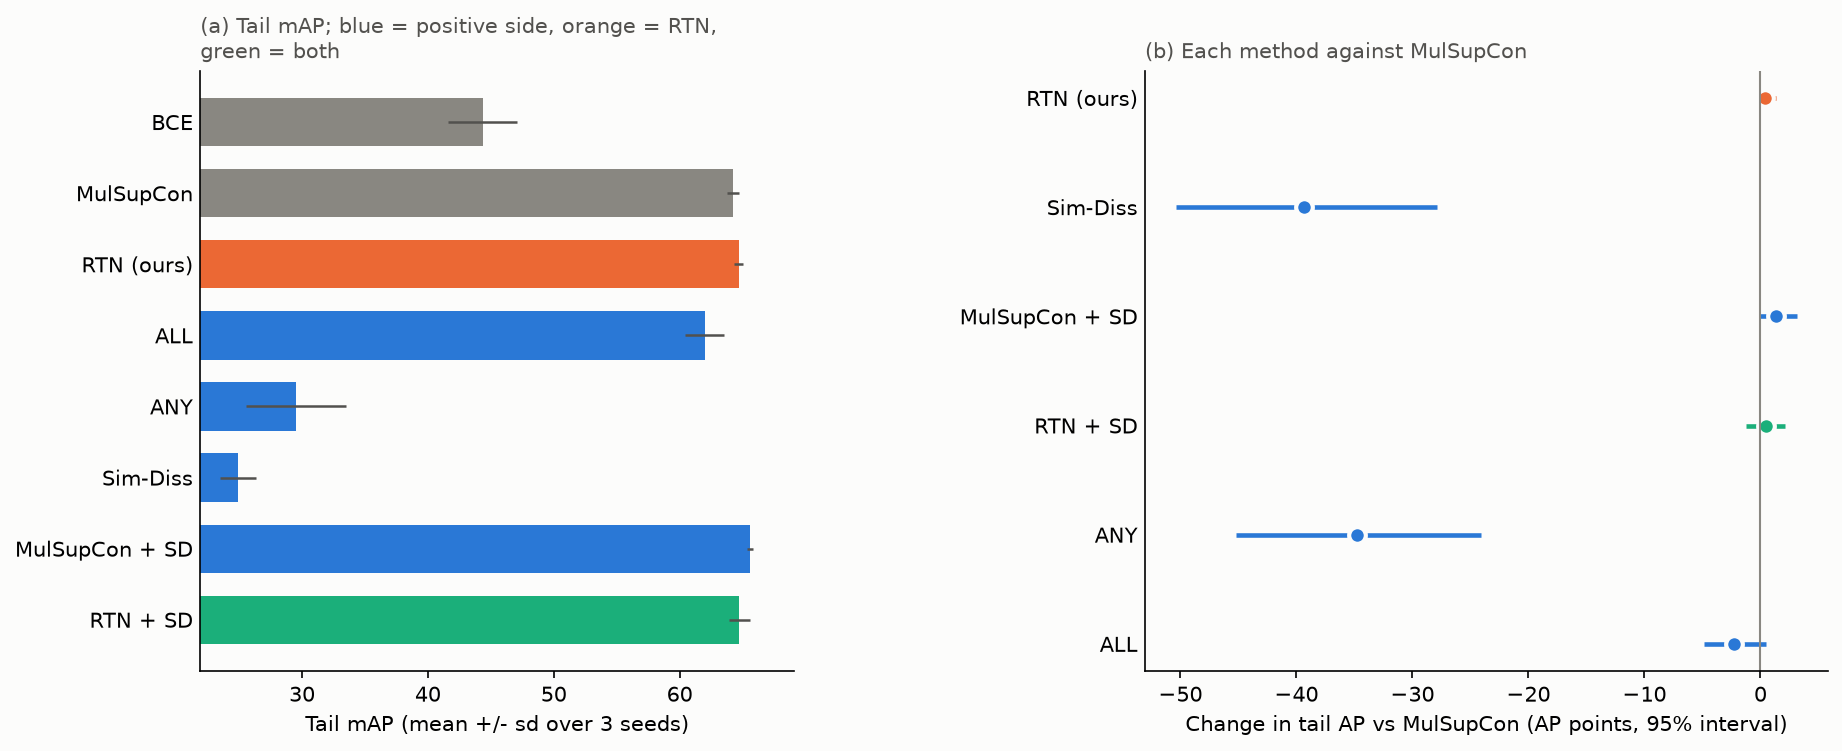

Saved coco_mlt\contrastive\round6.png


In [14]:
SURFACE, MUTED, INK = "#fcfcfb", "#898781", "#52514e"
FAMILY = {"bce": MUTED, "mulsupcon": MUTED, "all": "#2a78d6", "any": "#2a78d6",
          "simdiss": "#2a78d6", "mul_sd": "#2a78d6", "ours": "#eb6834",
          "ours_sd": "#1baf7a"}
fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(14, 5.2), facecolor=SURFACE,
                               gridspec_kw=dict(width_ratios=[1, 1.15], wspace=0.55))
vals = [group_map(k, "tail") for k in ORDER]
y = np.arange(len(ORDER))[::-1]
ax0.barh(y, [np.mean(v) for v in vals], height=0.68,
         xerr=[np.std(v, ddof=1) for v in vals],
         color=[FAMILY.get(k, MUTED) for k in ORDER],
         error_kw=dict(ecolor=INK, lw=1.2))
ax0.set_yticks(y)
ax0.set_yticklabels([SHORT[k] for k in ORDER])
ax0.set_xlabel("Tail mAP (mean +/- sd over 3 seeds)")
ax0.set_xlim(left=max(0, min(np.mean(v) for v in vals) - 3))
ax0.set_title("(a) Tail mAP; blue = positive side, orange = RTN,\n"
              "green = both", loc="left", fontsize=10, color=INK)
show = [k for k in ("ours", "simdiss", "mul_sd", "ours_sd", "any", "all") if k in RUNS]
yy = np.arange(len(show))[::-1]
for yi, k in zip(yy, show):
    m, lo, hi, _ = RES[(k, "mulsupcon")][0]
    ax1.hlines(yi, lo, hi, color=FAMILY[k], lw=2.2)
    ax1.plot(m, yi, "o", color=FAMILY[k], ms=8, mec=SURFACE, mew=2)
ax1.axvline(0, color=MUTED, lw=1)
ax1.set_yticks(yy)
ax1.set_yticklabels([SHORT[k] for k in show])
ax1.set_xlabel("Change in tail AP vs MulSupCon (AP points, 95% interval)")
ax1.set_title("(b) Each method against MulSupCon", loc="left", fontsize=10,
              color=INK)
for a in (ax0, ax1):
    a.set_facecolor(SURFACE)
    for side in ("top", "right"):
        a.spines[side].set_visible(False)
    a.tick_params(axis="y", length=0)
FIG = os.path.join(OUT, "round6.png")
fig.savefig(FIG, dpi=150, bbox_inches="tight", facecolor=SURFACE)
plt.close(fig)
display(Image(filename=FIG))
print(f"Saved {FIG}")

## Step 11: the dataset (for the report)

Label frequency, labels per image, co-occurrence and imbalance in the
1,909 training images (the evaluation images for comparison). IRLbl of
a class is the count of the most frequent class divided by its own
count; MeanIR and MaxIR are its mean and largest value over classes.
The co-occurrence panel shows, for each class (row), the share of its
training images that also contain each other class (column), with
classes sorted from most to least frequent.

,training (COCO-MLT),evaluation (COCO val2017)
images,1909,5000
labels per image (mean),4.36,2.93
labels per image (median),4.0,2.0
label density,0.054,0.037
distinct label sets,1491,2223
"images per class, min-max",6-1128,8-2693
MeanIR,49.4,31.9
MaxIR,188.0,336.6


,tail class,training images,most frequent companions (share of its images),images with a head class
10,bear,6,"person 67%, backpack 17%, book 17%",67%
23,hair drier,6,"bottle 100%, sink 50%, chair 33%",100%
11,zebra,7,"person 86%, car 57%, bench 14%",100%
7,sheep,7,"person 86%, handbag 43%, truck 29%",100%
12,giraffe,7,"person 100%, handbag 43%, potted plant 29%",100%
9,elephant,8,"person 100%, bicycle 12%, car 12%",100%
15,snowboard,8,"person 100%, skis 38%",100%
4,parking meter,8,"car 88%, person 50%, truck 25%",100%
21,toaster,9,"microwave 78%, oven 78%, dining table 67%",100%
0,airplane,9,"person 78%, car 33%, truck 33%",100%


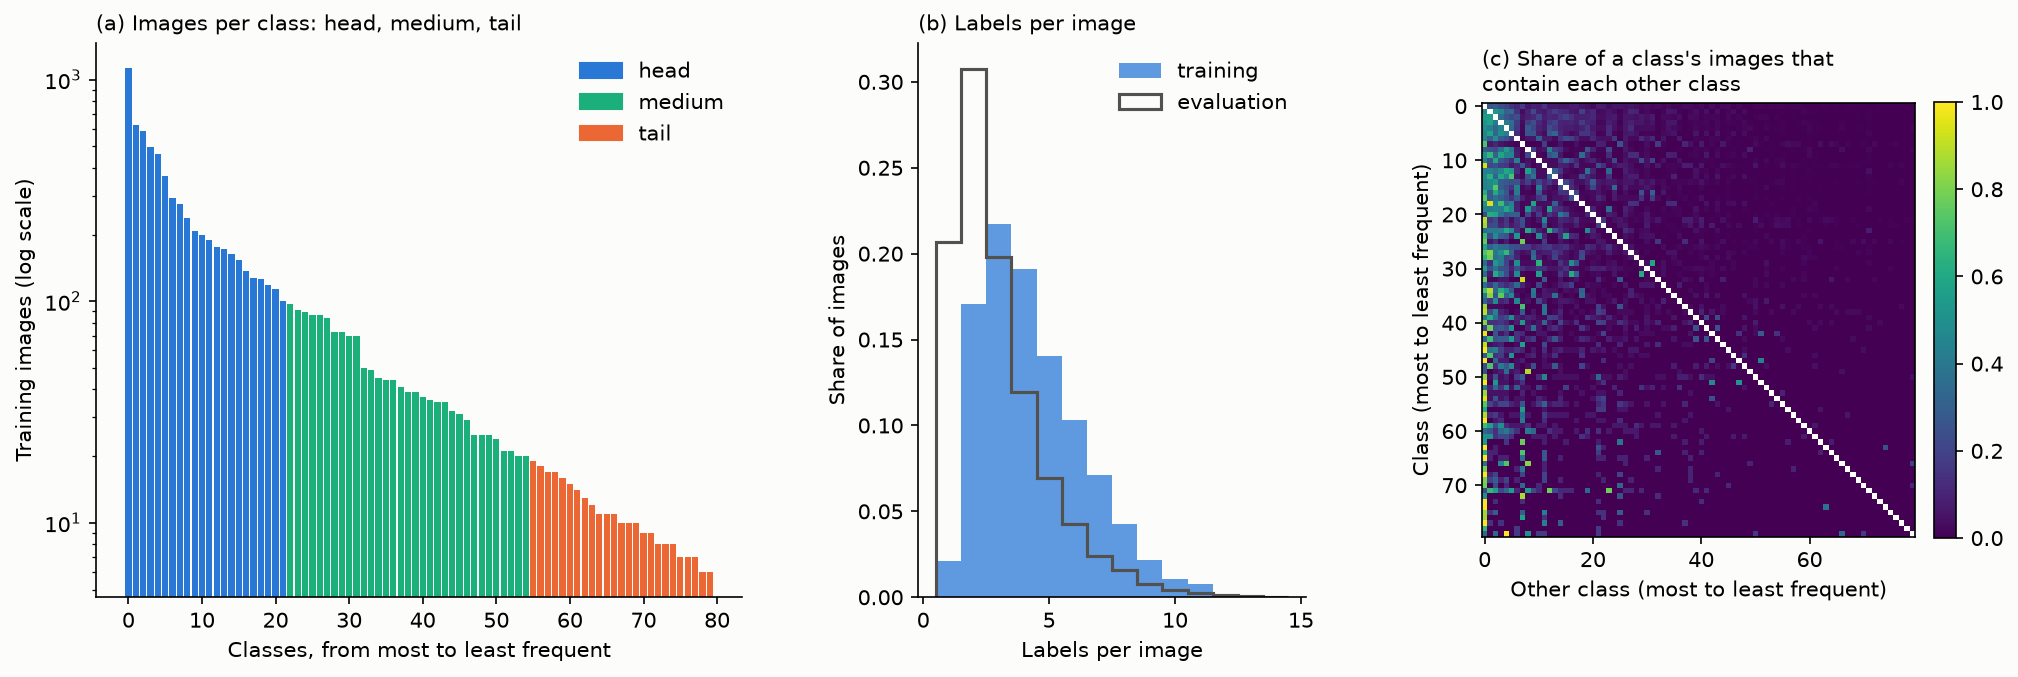

Saved coco_mlt\contrastive\dataset_analysis.png


In [15]:
def stats(Y):
    Yb_ = Y > 0.5
    n_c = Yb_.sum(0)
    card = Yb_.sum(1)
    ir = n_c.max() / np.maximum(n_c, 1)
    sets = {tuple(np.flatnonzero(r)) for r in Yb_}
    return {"images": int(len(Y)), "labels per image (mean)": round(float(card.mean()), 2),
            "labels per image (median)": float(np.median(card)),
            "label density": round(float(card.mean() / Y.shape[1]), 3),
            "distinct label sets": len(sets),
            "images per class, min-max": f"{int(n_c.min())}-{int(n_c.max())}",
            "MeanIR": round(float(ir.mean()), 1), "MaxIR": round(float(ir.max()), 1)}


dataset_stats = pd.DataFrame({"training (COCO-MLT)": stats(Y_all),
                              "evaluation (COCO val2017)": stats(Y_test)})
display(dataset_stats)

n_c = (Y_all > 0.5).sum(0)
order = np.argsort(-n_c, kind="stable")
co = (Y_all.T @ Y_all) / np.maximum(n_c, 1)[:, None]       # P(column | row)
np.fill_diagonal(co, np.nan)
rows = []
for t in TAIL:
    pr = co[t].copy()
    top = [c for c in np.argsort(-np.nan_to_num(pr, nan=-1)) if c != t][:3]
    rows.append({"tail class": names[t], "training images": int(n_c[t]),
                 "most frequent companions (share of its images)":
                 ", ".join(f"{names[c]} {100 * pr[c]:.0f}%" for c in top if pr[c] > 0),
                 "images with a head class": f"{100 * float(((Y_all[Y_all[:, t] > 0.5][:, GROUPS['head']] > 0.5).any(1)).mean()):.0f}%"})
tail_companions = pd.DataFrame(rows).sort_values("training images")
display(tail_companions)

COH = {"head": "#2a78d6", "medium": "#1baf7a", "tail": "#eb6834"}
fig = plt.figure(figsize=(16, 4.8), facecolor=SURFACE)
gs = fig.add_gridspec(1, 3, width_ratios=[1.5, 0.9, 1.1], wspace=0.35)
a0, a1, a2 = (fig.add_subplot(gs[i]) for i in range(3))
a0.bar(np.arange(L), n_c[order], color=[COH[cohort[j]] for j in order], width=0.85)
a0.set_yscale("log")
a0.set_xlabel("Classes, from most to least frequent")
a0.set_ylabel("Training images (log scale)")
a0.set_title("(a) Images per class: head, medium, tail", loc="left", fontsize=10)
from matplotlib.patches import Patch
a0.legend(handles=[Patch(color=col, label=g) for g, col in COH.items()],
          frameon=False)
card_tr = (Y_all > 0.5).sum(1)
card_te = (Y_test > 0.5).sum(1)
bins = np.arange(0.5, max(card_tr.max(), card_te.max()) + 1.5)
a1.hist(card_tr, bins=bins, density=True, color="#2a78d6", alpha=0.75,
        label="training")
a1.hist(card_te, bins=bins, density=True, histtype="step", color=INK, lw=1.5,
        label="evaluation")
a1.set_xlabel("Labels per image")
a1.set_ylabel("Share of images")
a1.set_title("(b) Labels per image", loc="left", fontsize=10)
a1.legend(frameon=False)
im = a2.imshow(co[np.ix_(order, order)], cmap="viridis", vmin=0, vmax=1,
               interpolation="nearest")
a2.set_xlabel("Other class (most to least frequent)")
a2.set_ylabel("Class (most to least frequent)")
a2.set_title("(c) Share of a class's images that\ncontain each other class",
             loc="left", fontsize=10)
fig.colorbar(im, ax=a2, fraction=0.046, pad=0.04)
for a in (a0, a1):
    a.set_facecolor(SURFACE)
    for side in ("top", "right"):
        a.spines[side].set_visible(False)
FIG_D = os.path.join(OUT, "dataset_analysis.png")
fig.savefig(FIG_D, dpi=150, bbox_inches="tight", facecolor=SURFACE)
plt.close(fig)
display(Image(filename=FIG_D))
print(f"Saved {FIG_D}")

## Step 12: time on the GPU and on the CPU (for the report)

Times a short stretch of contrastive pretraining (MulSupCon and RTN
losses) and of fine-tuning on this computer's GPU and on its CPU, and
estimates one full training from them (150,000 pretraining steps plus
the average number of fine-tuning epochs of the MulSupCon runs). These
are measured numbers you can report; one full run on the CPU is not
needed.

In [16]:
def time_device(dev, iters=200):
    Xf_, Yf_ = Xf.to(dev), Yf.to(dev)
    Xd_, Yd_, Xt_ = Xd.to(dev), Yd.to(dev), Xt.to(dev)
    out = {}
    for kind in ("uniform", "relation"):
        kw = rcr.pretrain_kwargs(kind, PROBE[kind], D)
        cfg = dict(PT_CFG, epochs=1, iters_per_epoch=iters)
        pretrain(Xf_, Yf_, seed=0, device=dev, cfg=dict(cfg, iters_per_epoch=20),
                 **kw)
        if dev == "cuda":
            torch.cuda.synchronize()
        t0 = time.time()
        pretrain(Xf_, Yf_, seed=0, device=dev, cfg=cfg, **kw)
        if dev == "cuda":
            torch.cuda.synchronize()
        out[kind] = (time.time() - t0) / iters
    probe = dict(FT_CFG, official_epochs=3, max_epochs=3)
    finetune(Xf_, Yf_, Xd_, Yd_, Xt_, 0, dev, dict(probe, official_epochs=1,
                                                   max_epochs=1))
    if dev == "cuda":
        torch.cuda.synchronize()
    t0 = time.time()
    finetune(Xf_, Yf_, Xd_, Yd_, Xt_, 0, dev, probe)
    if dev == "cuda":
        torch.cuda.synchronize()
    out["ft_epoch"] = (time.time() - t0) / 3
    return out


devices = [DEVICE] + (["cpu"] if TIME_CPU and DEVICE != "cpu" else [])
TIMES = {}
for dev in devices:
    print(f"Timing on {dev}...")
    TIMES[dev] = time_device(dev)
ft_epochs = float(np.mean([int(RUNS["mulsupcon"][s]["epochs_run"]) for s in SEEDS]))
rows = []
for dev, t in TIMES.items():
    for kind, label in (("uniform", "MulSupCon"), ("relation", "RTN")):
        full = (t[kind] * ITERS + t["ft_epoch"] * ft_epochs) / 60
        rows.append({"device": "GPU" if dev == "cuda" else "CPU",
                     "loss": label,
                     "ms per pretraining step": round(1000 * t[kind], 2),
                     "s per fine-tuning epoch": round(t["ft_epoch"], 2),
                     "minutes per full training (estimate)": round(full, 1)})
timing = pd.DataFrame(rows)
print(f"Full training = {ITERS:,} pretraining steps + {ft_epochs:.0f} fine-tuning "
      f"epochs (average of the MulSupCon runs). CPU threads: "
      f"{torch.get_num_threads()}.")
timing

Timing on cuda...
Timing on cpu...
Full training = 150,000 pretraining steps + 63 fine-tuning epochs (average of the MulSupCon runs). CPU threads: 8.


,device,loss,ms per pretraining step,s per fine-tuning epoch,minutes per full training (estimate)
0,GPU,MulSupCon,11.63,0.24,29.3
1,GPU,RTN,11.92,0.24,30.1
2,CPU,MulSupCon,13.65,0.26,34.4
3,CPU,RTN,18.79,0.26,47.3


## Step 13: save the results

In [17]:
results_table.to_csv(os.path.join(OUT, "results_round6.csv"), index=False)
grid_2x2.to_csv(os.path.join(OUT, "tail_2x2_round6.csv"))
comparisons.to_csv(os.path.join(OUT, "comparisons_round6.csv"), index=False)
effects.to_csv(os.path.join(OUT, "effects_2x2_round6.csv"), index=False)
type_levels.to_csv(os.path.join(OUT, "by_type_gaps_round6.csv"), index=False)
type_changes.to_csv(os.path.join(OUT, "by_type_changes_round6.csv"), index=False)
dataset_stats.to_csv(os.path.join(OUT, "dataset_stats.csv"))
tail_companions.to_csv(os.path.join(OUT, "tail_companions.csv"), index=False)
timing.to_csv(os.path.join(OUT, "timing_gpu_cpu.csv"), index=False)
pd.DataFrame(selection_rows).to_csv(os.path.join(OUT, "selection_round6.csv"),
                                    index=False)
with open(os.path.join(OUT, "summary_round6.txt"), "w", encoding="utf-8") as f:
    f.write("\n".join(lines) + "\n\n" + results_table.to_string(index=False)
            + "\n\n2 x 2 (tail mAP):\n" + grid_2x2.to_string()
            + "\n\n" + effects.to_string(index=False)
            + "\n\nComparisons:\n" + comparisons.to_string(index=False)
            + "\n\nBy relation type:\n" + type_changes.to_string(index=False)
            + "\n\nTiming:\n" + timing.to_string(index=False) + "\n")
print("\n".join(lines))
print(f"\nSaved the tables, round6.png, dataset_analysis.png and summary_round6.txt "
      f"to {os.path.abspath(OUT)}")

RTN: MulSupCon + relation-typed negatives (ours) vs MulSupCon: NOT SHOWN  (tail AP +0.42 [-0.36, +1.30], higher in 3 of 3 seeds; related-class gap reduced under both controls: False; head AP -0.77)
Similarity-Dissimilarity (Huang et al., 2026) vs MulSupCon: NOT SHOWN  (tail AP -39.36 [-50.38, -27.92], higher in 0 of 3 seeds; related-class gap reduced under both controls: False; head AP +3.56)
MulSupCon + Sim-Diss positive weights vs MulSupCon: NOT SHOWN  (tail AP +1.31 [-0.16, +3.13], higher in 3 of 3 seeds; related-class gap reduced under both controls: False; head AP +1.59)
RTN + Sim-Diss positive weights vs MulSupCon: NOT SHOWN  (tail AP +0.45 [-1.23, +2.16], higher in 2 of 3 seeds; related-class gap reduced under both controls: False; head AP +1.12)
ANY: at least one shared label vs MulSupCon: NOT SHOWN  (tail AP -34.77 [-45.19, -24.06], higher in 0 of 3 seeds; related-class gap reduced under both controls: False; head AP -1.66)
ALL: same label set as the anchor image vs MulSupCon:

## How to read the results

- **Step 7, 2 x 2 table:** compare the rows (does RTN help, with equal
  or with Sim-Diss positives?) and the columns (do Sim-Diss weights
  help, with equal or with relation-typed negatives?).
- **Step 9, head-to-head:** RTN against the Similarity-Dissimilarity
  loss on the tail. **2 x 2 effects:** an interaction near zero means
  the positive and negative weightings add up; below zero means they
  overlap.
- **Step 8:** RTN is designed to lower the gap for related classes;
  positive weighting is not aimed at it, so if Sim-Diss changes the
  gap, that is a side effect worth reporting either way.

## Limitations

- Round 6 was designed after rounds 1-5, so its verdicts are
  exploratory and need confirming on a second dataset.
- The Similarity-Dissimilarity factor is applied to each positive's
  log-probability term. Written inside the log, as in Eq. 13 of the
  paper, it would leave training identical to ANY (Step 3); the
  authors' code may differ in other details.
- ALL, ANY and Similarity-Dissimilarity use one anchor per image, as in
  the paper, inside this pipeline (momentum encoder, queue of 256,
  temperature 0.1, frozen CLIP features with an MLP); the paper used
  end-to-end encoders, in-batch candidates and temperature 0.07, so
  absolute numbers are not comparable with it.
- Three seeds; settings of rounds 1-2 were chosen on one seed's dev set.